# M6 EnCom Metagenomics - co-occurrence network analysis

In [1]:
#import necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy
import seaborn as sns
from scipy.stats import ttest_ind
import random
import networkx as nx
import os
import glob
import pickle
mpl.rcParams['font.family'] = 'Helvetica'
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

sns.set_style('white')
sns.set_context('paper')

In [2]:
#Print package versions for replicability
print('\n'.join(f'{m.__name__}=={m.__version__}' for m in globals().values() if getattr(m, '__version__', None)))

pandas==3.0.1
numpy==2.4.2
matplotlib==3.10.8
scipy==1.17.1
seaborn==0.13.2
networkx==3.6.1


## First, need to create subsets/slices of the abundance data corresponding to sample conditions

In [3]:
#Before we get too deep, let's grab information about mean rel abundance for each bin across all samples and for each pH subset
#This is the same abundance data used in the community composition notebook.

bin_abunds_df = pd.read_csv('./data/mean_coverage_Q2Q3.txt',sep='\t',index_col='bins') #read in mean Q2Q3 data for each MAG across all samples
bin_order = ['Bin_1','Bin_2','Bin_3','Bin_4','Bin_5','Bin_6','Bin_7','Bin_8','Bin_9','Bin_10','Bin_11','Bin_12','Bin_13',
             'Bin_14','Bin_15','Bin_16','Bin_17','Bin_18','Bin_19','Bin_20','Bin_21','Bin_22','Bin_23','Bin_24','Bin_25',
             'Bin_26','Bin_27','Bin_28','Bin_29','Bin_30','Bin_31','Bin_32','Bin_33','Bin_34','Bin_35','Bin_36','Bin_37',
             'Bin_38','Bin_39','Bin_40','Bin_41'] #these get out of order b/c numbers and strings so put in order manually

bin_abunds_df = bin_abunds_df.reindex(bin_order) #reorder the index so it matches the desired order

bin_abunds_df_rel = bin_abunds_df.div(bin_abunds_df.sum()).mul(100) #divide each column by its sum and multiply each value by 100 to get % rel abundance

#Create a dictionary with the mean abundance for each MAG across all the samples; use this downstream for scaling network node sizes
all_mean_bin_rel_abund_dict = {}
for i in range(len(bin_order)): #use indexes to loop over the bin order so that iloc can be used to access row means
    all_mean_bin_rel_abund_dict[bin_order[i]] = bin_abunds_df_rel.T.mean().iloc[i]

In [4]:
#Use CheckM data to get list of bins above completeness threshold
checkM_df = pd.read_csv('./data/CheckM_summary_table.tsv',sep='\t')
checkM_df['bin_id'] = checkM_df['Bin Name'].str.split('-',expand=True)[0]

#For the networks, we use a more relaxed threshold of 50% completeness to maximize inclusion of trustworthy-ish biological units in network construction
percent_completion_threshold = 50

good_bin_list = checkM_df[checkM_df['Completeness']>=percent_completion_threshold]['bin_id'].to_list() #making a list of good bins if they're above completion threshold
print(good_bin_list)

['Bin_1', 'Bin_10', 'Bin_11', 'Bin_12', 'Bin_13', 'Bin_14', 'Bin_15', 'Bin_16', 'Bin_18', 'Bin_2', 'Bin_20', 'Bin_21', 'Bin_22', 'Bin_3', 'Bin_37', 'Bin_39', 'Bin_40', 'Bin_41', 'Bin_5', 'Bin_6', 'Bin_7', 'Bin_8', 'Bin_9']


In [5]:
#This is the above good_bin_list at the 50% threshold, manually reordered because python doesn't sort string numbers like a human
better_bin_list = ['Bin_1', 'Bin_2', 'Bin_3', 'Bin_5', 'Bin_6', 'Bin_7', 'Bin_8', 'Bin_9',
                   'Bin_10', 'Bin_11', 'Bin_12', 'Bin_13', 'Bin_14', 'Bin_15', 'Bin_16', 'Bin_18',
                   'Bin_20', 'Bin_21', 'Bin_22',  'Bin_37', 'Bin_39', 'Bin_40', 'Bin_41']

#Boolean check to make sure I didn't miss anything in my reordering
set(good_bin_list) == set(better_bin_list)

True

In [6]:
#Sample conditions/metadata 
sample_info_df = pd.read_csv('./data/EnCom_all_sample_info_misc_data_layer.txt',sep='\t') #read into dataframe

sample_order = sample_info_df.sort_values(['Media','Timepoint','C source','pH','[NO3]'])['samples'].to_list() #sort by these variables in order for optimal grouping and create list to use to order columns for abund df

In [7]:
#Here, let's pause and actually re-run fastspar on subsets of samples (e.g. pH 4.5 or [NO3] 10mM, etc.)
#We want to know how co-occurrence correlation varies as a function of the conditions. 
#The fastspar algorithm requires a biom formatted version of the coverage table.

#Let's slice this table up and generate subsetted versions to run and plot with.
bin_abunds_df_biom = pd.read_csv('./data/mean_coverage_Q2Q3_biom.txt',sep='\t',index_col=0) #identical to bin_abunds_df but the index is named '#OTU ID' to match 
bin_abunds_df_biom

,NLDM_T1_A1,NLDM_T1_A2,NLDM_T1_A3,NLDM_T1_A4,NLDM_T1_A5,NLDM_T1_A6,NLDM_T1_A7,NLDM_T1_A8,NLDM_T1_B1,NLDM_T1_B2,...,SGW_T3_H11,SGW_T3_H12,SGW_T3_H2,SGW_T3_H3,SGW_T3_H4,SGW_T3_H5,SGW_T3_H6,SGW_T3_H7,SGW_T3_H8,SGW_T3_H9
#OTU ID,,,,,,,,,,,,,,,,,,,,,
Bin_1,4.693395,0.246516,0.145388,0.197378,0.149286,0.086062,15.450627,29.786401,0.074371,3.793438,...,0.020653,21.131790,0.772005,12.788279,21.462934,3.267888,1.657753,0.775878,3.977884,10.352153
Bin_10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000694,0.037745,0.002576,0.000000,0.000000,0.002488,0.001715,0.003942,0.002719,0.005530
Bin_11,0.001296,0.002500,0.002518,0.000085,0.166293,0.008061,0.479003,22.223054,0.002560,0.001213,...,0.000000,0.000000,0.000000,0.000000,0.001377,0.000000,0.000000,0.000000,0.000000,0.000000
Bin_12,0.010727,0.004837,0.009179,0.002899,0.001860,0.000000,0.001580,1.186442,0.002557,0.007571,...,0.000000,0.003472,0.000000,0.000000,0.069946,0.000000,0.001599,0.000000,0.000000,0.000000
Bin_13,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Bin_14,0.044372,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Bin_15,0.013125,0.142421,0.251672,0.216067,0.013134,0.388107,0.589499,0.184075,0.396085,0.083767,...,0.000000,0.000000,0.000000,0.000000,0.064930,0.000000,0.000000,0.000000,0.000000,0.000000
Bin_16,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000096,0.032602,0.000000,0.000000,0.074742,0.000000,0.000000,0.000000,0.000000,0.000000
Bin_17,0.001168,0.118282,0.218090,0.358795,0.002317,0.232443,0.154636,0.434953,0.485517,0.046712,...,0.000000,0.000000,0.000000,0.000000,0.192523,0.000000,0.000000,0.000000,0.000000,0.000000


In [8]:
#Here, we create lists of sample names that correspond to different conditions. There is a lot of overlap here.
#We are going to focus on only using the NLDM T2 and SGW T3 samples here to use our best approximation of the state the enrichments are heading to.

#Sample lists for each medium
NLDM_list = sample_info_df[sample_info_df['Media'] == 'NLDM'].samples.to_list()
SGW_list = sample_info_df[sample_info_df['Media'] == 'SGW'].samples.to_list()

#Separate by timepoint
T1_NLDM_list = [x for x in NLDM_list if 'T1' in x]
T2_NLDM_list = [x for x in NLDM_list if 'T2' in x]
T1_SGW_list = [x for x in SGW_list if 'T1' in x]
T3_SGW_list = [x for x in SGW_list if 'T3' in x]

#Sample lists for each C source; SGW media only
c_acetate_list = sample_info_df[sample_info_df['C source'] == 'acetate'].samples.to_list()
c_glucose_list = sample_info_df[sample_info_df['C source'] == 'glucose'].samples.to_list()
c_citrate_list = sample_info_df[sample_info_df['C source'] == 'citrate'].samples.to_list()
c_pyruvate_list = sample_info_df[sample_info_df['C source'] == 'pyruvate'].samples.to_list()
c_lactate_list = sample_info_df[sample_info_df['C source'] == 'lactate'].samples.to_list()
c_none_list = sample_info_df[sample_info_df['C source'] == 'no C'].samples.to_list()

#All T2 and T3 timepoints; use this as the 'All' condition below
T2_T3_samples = sample_info_df[sample_info_df['Timepoint']!='T1']['samples']

#NLDM T2 pH sample splits
T2_pH4_samples = sample_info_df[sample_info_df['samples'].isin(T2_NLDM_list)].loc[sample_info_df['pH']==4.5]['samples']
T2_pH6_samples = sample_info_df[sample_info_df['samples'].isin(T2_NLDM_list)].loc[sample_info_df['pH']==6]['samples']
T2_pH7_samples = sample_info_df[sample_info_df['samples'].isin(T2_NLDM_list)].loc[sample_info_df['pH']==7]['samples']

#NLDM T2 NO3 sample splits (low and high bins to maximize sample replication; too few for each individual concentration)
T2_low_NO3_samples = sample_info_df[sample_info_df['samples'].isin(T2_NLDM_list)].loc[sample_info_df['[NO3]'].isin([5,10,15])]['samples']
T2_high_NO3_samples = sample_info_df[sample_info_df['samples'].isin(T2_NLDM_list)].loc[sample_info_df['[NO3]'].isin([20,30,40])]['samples']

#T3 C source sample splits
T3_glucose_samples = sample_info_df[sample_info_df['samples'].isin(c_glucose_list)]['samples']
T3_acetate_samples = sample_info_df[sample_info_df['samples'].isin(c_acetate_list)]['samples']
T3_citrate_samples = sample_info_df[sample_info_df['samples'].isin(c_citrate_list)]['samples']
T3_lactate_samples = sample_info_df[sample_info_df['samples'].isin(c_lactate_list)]['samples']
T3_pyruvate_samples = sample_info_df[sample_info_df['samples'].isin(c_pyruvate_list)]['samples']

#SGW-C sources T3 pH sample splits
T3_glucose_pH4_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_glucose_list)].loc[sample_info_df['pH']==4.5]['samples']
T3_glucose_pH6_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_glucose_list)].loc[sample_info_df['pH']==6]['samples']
T3_glucose_pH7_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_glucose_list)].loc[sample_info_df['pH']==7]['samples']

T3_acetate_pH4_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_acetate_list)].loc[sample_info_df['pH']==4.5]['samples']
T3_acetate_pH6_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_acetate_list)].loc[sample_info_df['pH']==6]['samples']
T3_acetate_pH7_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_acetate_list)].loc[sample_info_df['pH']==7]['samples']

T3_citrate_pH4_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_citrate_list)].loc[sample_info_df['pH']==4.5]['samples']
T3_citrate_pH6_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_citrate_list)].loc[sample_info_df['pH']==6]['samples']
T3_citrate_pH7_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_citrate_list)].loc[sample_info_df['pH']==7]['samples']

T3_lactate_pH4_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_lactate_list)].loc[sample_info_df['pH']==4.5]['samples']
T3_lactate_pH6_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_lactate_list)].loc[sample_info_df['pH']==6]['samples']
T3_lactate_pH7_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_lactate_list)].loc[sample_info_df['pH']==7]['samples']

T3_pyruvate_pH4_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_pyruvate_list)].loc[sample_info_df['pH']==4.5]['samples']
T3_pyruvate_pH6_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_pyruvate_list)].loc[sample_info_df['pH']==6]['samples']
T3_pyruvate_pH7_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_pyruvate_list)].loc[sample_info_df['pH']==7]['samples']

#SGW-C sources T3 NO3 samples
T3_glucose_low_NO3_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_glucose_list)].loc[sample_info_df['[NO3]'].isin([5,10,15])]['samples']
T3_glucose_high_NO3_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_glucose_list)].loc[sample_info_df['[NO3]'].isin([20,30,40])]['samples']

T3_acetate_low_NO3_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_acetate_list)].loc[sample_info_df['[NO3]'].isin([5,10,15])]['samples']
T3_acetate_high_NO3_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_acetate_list)].loc[sample_info_df['[NO3]'].isin([20,30,40])]['samples']

T3_citrate_low_NO3_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_citrate_list)].loc[sample_info_df['[NO3]'].isin([5,10,15])]['samples']
T3_citrate_high_NO3_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_citrate_list)].loc[sample_info_df['[NO3]'].isin([20,30,40])]['samples']

T3_lactate_low_NO3_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_lactate_list)].loc[sample_info_df['[NO3]'].isin([5,10,15])]['samples']
T3_lactate_high_NO3_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_lactate_list)].loc[sample_info_df['[NO3]'].isin([20,30,40])]['samples']

T3_pyruvate_low_NO3_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_pyruvate_list)].loc[sample_info_df['[NO3]'].isin([5,10,15])]['samples']
T3_pyruvate_high_NO3_samples = sample_info_df[sample_info_df['samples'].isin(T3_SGW_list)&sample_info_df['samples'].isin(c_pyruvate_list)].loc[sample_info_df['[NO3]'].isin([20,30,40])]['samples']

#Make a dict of sample subset lists for writing out files to run fastspar
sparCC_subset_list_dict = {'T2_T3_all': T2_T3_samples, #all later timepoints samples
                           'T2_NLDM':T2_NLDM_list,'T3_glucose':T3_glucose_samples, 'T3_citrate':T3_citrate_samples, 'T3_lactate':T3_lactate_samples, 'T3_pyruvate':T3_pyruvate_samples, 'T3_acetate':T3_acetate_samples, #C source splits
                           'T2_NLDM_pH4':T2_pH4_samples, 'T2_NLDM_pH6':T2_pH6_samples, 'T2_NLDM_pH7':T2_pH7_samples, #NLDM pH splits
                           'T2_NLDM_low_NO3':T2_low_NO3_samples, 'T2_NLDM_high_NO3':T2_high_NO3_samples, #NLDM NO3 splits
                           'T3_glucose_pH4':T3_glucose_pH4_samples, 'T3_glucose_pH7':T3_glucose_pH7_samples, #C-source pH splits
                           'T3_acetate_pH4':T3_acetate_pH4_samples, 'T3_acetate_pH7':T3_acetate_pH7_samples, 
                           'T3_citrate_pH4':T3_citrate_pH4_samples, 'T3_citrate_pH7':T3_citrate_pH7_samples, 
                           'T3_lactate_pH4':T3_lactate_pH4_samples, 'T3_lactate_pH7':T3_lactate_pH7_samples, 
                           'T3_pyruvate_pH4':T3_pyruvate_pH4_samples, 'T3_pyruvate_pH7':T3_pyruvate_pH7_samples,
                           'T3_glucose_low_NO3':T3_glucose_low_NO3_samples, 'T3_glucose_high_NO3':T3_glucose_high_NO3_samples, #C-source NO3 splits
                           'T3_acetate_low_NO3':T3_acetate_low_NO3_samples, 'T3_acetate_high_NO3':T3_acetate_high_NO3_samples, 
                           'T3_citrate_low_NO3':T3_citrate_low_NO3_samples, 'T3_citrate_high_NO3':T3_citrate_high_NO3_samples, 
                           'T3_lactate_low_NO3':T3_lactate_low_NO3_samples, 'T3_lactate_high_NO3':T3_lactate_high_NO3_samples, 
                           'T3_pyruvate_low_NO3':T3_pyruvate_low_NO3_samples, 'T3_pyruvate_high_NO3':T3_pyruvate_high_NO3_samples
                            }

#loop to write out biom_formatted matrices to run with fastspar
for k,v in sparCC_subset_list_dict.items():
    samples = v
    name = k
    df_sub = bin_abunds_df_biom[bin_abunds_df_biom.index.isin(good_bin_list)][samples] #subset mean coverage dict to the samples for the subset and only counting the "good" (>50% complete) bins
    #df_sub.to_csv(f'./data/fastspar/{name}_bin_abunds_biom.txt',sep='\t') #write out each abundance data for each condition to a biom formatted OTU table

## Fastspar (SparCC) based network analysis looking at bin co-occurrence

Fastspar was run using the command line/ scripts outside of this notebook.  <br>
See https://github.com/scwatts/fastspar for more detailed information. <br>
Here is a brief description of what that looked like:
```sh
#Running fastspar on the full dataset, you need the 'median_correlation.tsv' from this initial step for the last step to see how your values compare to random: 
fastspar --otu_table ./data/mean_coverage_Q2Q3_biom.txt --correlation ./data/fastspar/all/manual_bins_fastspar_median_correlation.tsv --covariance ./data/fastspar/all/manual_bins_fastspar_median_covariance.tsv -i 1000 -t 10

#bootstrapping, make 1000 random counts in the shape of the whole dataset:
mkdir ./data/fastspar/all/fastspar_stats/full_set_test/bootstrap_counts 
fastspar_bootstrap --otu_table ./data/mean_coverage_Q2Q3_biom.txt --number 1000 --prefix ./data/fastspar/all/fastspar_stats/full_set_test/bootstrap_counts/full_dataset

#run the correlation analysis on all the random datasets:
mkdir ./data/fastspar/all/fastspar_stats/full_set_test/bootstrap_correlation
parallel fastspar --otu_table {} --correlation ./data/fastspar/all/fastspar_stats/full_set_test/bootstrap_correlation/cor_{/} --covariance ./data/fastspar/all/fastspar_stats/full_set_test/bootstrap_correlation/cov_{/} -i 5 ::: ./data/fastspar/all/fastspar_stats/full_set_test/bootstrap_counts/*

#calculate the exact p-values:
fastspar_pvalues --otu_table ./data/mean_coverage_Q2Q3_biom.txt --correlation ./data/fastspar/all/manual_bins_fastspar_median_correlation.tsv --prefix ./data/fastspar/allfastspar_stats/full_set_test/bootstrap_correlation/cor_full_dataset_ --permutations 1000 --outfile  ./data/fastspar/allfastspar_stats/full_set_test/pvalues.tsv
```


### Running Fastspar on the ensemble

This is the script I wrote to run Fastspar on each of the subsets generated above:

```sh
for file in ././data/fastspar/*_abunds_biom.txt
do
    mkdir ./data/fastspar/fastspar_stats/$(basename $file .txt)
    mkdir ./data/fastspar/fastspar_stats/$(basename $file .txt)/bootstrap_counts
    mkdir ./data/fastspar/fastspar_stats/$(basename $file .txt)/bootstrap_correlation
    fastspar_bootstrap --otu_table $file --number 1000 --prefix ./data/fastspar/fastspar_stats/$(basename $file .txt)/bootstrap_counts/$(basename $file .txt)
    parallel fastspar --otu_table {} --correlation ./data/fastspar/$(basename $file .txt)/bootstrap_correlation/cor_{/} --covariance ./data/fastspar/$(basename $file .txt)/bootstrap_correlation/cov_{/} -i 5 ::: ./data/fastspar/fastspar_stats/$(basename $file .txt)/bootstrap_counts/*
    fastspar_pvalues --otu_table $file --correlation ./data/fastspar/fastspar_stats/$(basename $file .txt)_fastspar_correlation.tsv --prefix ./data/fastspar/fastspar_stats/$(basename $file .txt)/bootstrap_correlation/cor_$(basename $file .txt) --permutations 1000 --outfile  ./data/fastspar/fastspar_stats/$(basename $file .txt)/pvalues.tsv
done
```

In [9]:
#Setting the 'All' condition here as the T2 and T3 samples with the good bins only
fastspar_bin_cc_df = pd.read_csv('./data/fastspar/T2_T3_all_bin_abunds_biom_fastspar_correlation.tsv',sep='\t')
fastspar_bin_cc_df

,#OTU ID,Bin_1,Bin_10,Bin_11,Bin_12,Bin_13,Bin_14,Bin_15,Bin_16,Bin_18,...,Bin_3,Bin_37,Bin_39,Bin_40,Bin_41,Bin_5,Bin_6,Bin_7,Bin_8,Bin_9
0,Bin_1,1.0000,-0.0251,0.0028,0.0435,-0.0703,0.0012,-0.0506,-0.0034,-0.0180,...,0.2442,0.0151,0.0275,0.0368,0.0328,0.0261,-0.0519,-0.0031,0.0164,0.0589
1,Bin_10,-0.0251,1.0000,0.0332,-0.0018,0.0080,0.0205,0.0301,0.0267,0.0013,...,-0.0307,-0.0042,-0.0109,-0.0385,-0.0153,0.0016,0.0092,-0.0275,-0.0223,-0.0095
2,Bin_11,0.0028,0.0332,1.0000,-0.0231,0.0202,0.0100,-0.0137,0.0105,0.0102,...,-0.0207,0.0063,0.0117,-0.0102,-0.0117,-0.0172,0.0102,0.0025,-0.0200,-0.0230
3,Bin_12,0.0435,-0.0018,-0.0231,1.0000,0.0003,-0.0126,-0.0121,0.0005,0.0211,...,0.0361,0.0081,-0.0188,-0.0121,-0.0010,0.0027,0.0188,-0.0209,-0.0375,-0.0161
4,Bin_13,-0.0703,0.0080,0.0202,0.0003,1.0000,0.0104,0.0192,-0.0115,0.0390,...,-0.0185,0.0188,-0.0124,0.0089,-0.0012,0.0087,0.0345,0.0053,-0.0332,-0.0334
5,Bin_14,0.0012,0.0205,0.0100,-0.0126,0.0104,1.0000,0.0003,-0.0096,0.0141,...,0.0193,0.0187,-0.0039,-0.0175,-0.0077,-0.0124,0.0049,0.0123,-0.0111,-0.0396
6,Bin_15,-0.0506,0.0301,-0.0137,-0.0121,0.0192,0.0003,1.0000,0.0335,0.0151,...,-0.0131,0.0048,0.0000,-0.0107,0.0190,-0.0022,0.0371,0.0062,-0.0069,-0.0224
7,Bin_16,-0.0034,0.0267,0.0105,0.0005,-0.0115,-0.0096,0.0335,1.0000,0.0348,...,-0.0482,-0.0116,-0.0159,-0.0328,-0.0122,-0.0059,0.0395,0.0027,-0.0243,-0.0138
8,Bin_18,-0.0180,0.0013,0.0102,0.0211,0.0390,0.0141,0.0151,0.0348,1.0000,...,-0.0279,-0.0040,-0.0336,-0.0405,0.0117,-0.0297,0.0141,-0.0234,-0.0166,-0.0080
9,Bin_2,0.3255,0.0122,-0.0038,0.0123,-0.0192,-0.0156,-0.0339,-0.0168,0.0047,...,0.0761,-0.0174,0.0205,0.0392,-0.0153,0.0123,-0.0402,-0.0427,0.0239,-0.0032


In [10]:
#NetworkX will build network graph objects from long format (melted) pandas dataframes, so let's restructure this data to fit.
fastspar_bin_cc_df_melt = fastspar_bin_cc_df.melt(id_vars=['#OTU ID']).rename({'#OTU ID':'bin'},axis=1) #Melt the data so we can build the network
fastspar_bin_cc_df_melt = fastspar_bin_cc_df_melt.loc[fastspar_bin_cc_df_melt['bin'] != fastspar_bin_cc_df_melt['variable']] #Drop the self-correlation rows; bin is node_i and variable is node_j, I just didn't rename the columns
fastspar_bin_cc_df_melt

,bin,variable,value
1,Bin_10,Bin_1,-0.0251
2,Bin_11,Bin_1,0.0028
3,Bin_12,Bin_1,0.0435
4,Bin_13,Bin_1,-0.0703
5,Bin_14,Bin_1,0.0012
...,...,...,...
523,Bin_41,Bin_9,0.0010
524,Bin_5,Bin_9,0.0047
525,Bin_6,Bin_9,-0.0367
526,Bin_7,Bin_9,0.0298


In [11]:
#Dictionaries to be used for renaming, color palettes, etc.

#For the network plots, let's rename the nodes so they match the newer labels on the anvio plots
bin_label_rename_dict = {
 'Bin_1':'Neor 1',
 'Bin_2':'Allo 2',
 'Bin_3':'Lysi 3',
 'Bin_4':'Neor 4',
 'Bin_5':'Robe 5',
 'Bin_6':'Arth 6',
 'Bin_7':'Paen 7',
 'Bin_8':'Meso 8',
 'Bin_9':'Noca 9',
 'Bin_10':'Lacu 10',
 'Bin_11':'Arth 11',
 'Bin_12':'Arth 12',
 'Bin_13':'Para 13',
 'Bin_14':'Baci 14',
 'Bin_15':'Arth 15',
 'Bin_16':'Jani 16',
 'Bin_17':'17',
 'Bin_18':'Arth 18',
 'Bin_19':'Arth 19',
 'Bin_20':'Flav 20',
 'Bin_21':'Fict 21',
 'Bin_22':'Cell 22',
 'Bin_23':'23',
 'Bin_24':'24',
 'Bin_25':'Arth 25',
 'Bin_26':'Aero 26',
 'Bin_27':'Baci 27',
 'Bin_28':'Arth 28',
 'Bin_29':'Noca 29',
 'Bin_30':'Noca 30',
 'Bin_31':'Stre 31',
 'Bin_32':'Stre 32',
 'Bin_33':'33',
 'Bin_34':'Neob 34',
 'Bin_35':'Paen 35',
 'Bin_36':'Robe 36',
 'Bin_37':'Micr 37',
 'Bin_38':'38',
 'Bin_39':'Noca 39',
 'Bin_40':'Noca 40',
 'Bin_41':'Arth 41'
}


#Before the plots are made, let's make a palette so the genus colors are consistent; genera for both bins and ASV data
genus_pal = {'Aeromicrobium':'xkcd:sky blue',
             'Janibacter':'xkcd:goldenrod',
             'Ciceribacter':'xkcd:grey blue',
             'Paenarthrobacter':'xkcd:mustard', 
             'Paenisporosarcina':'xkcd:beige', 
             'Allorhizobium':'xkcd:grey blue', 
             'Arthrobacter':'xkcd:rust', 
             'Allorhizobium-Neorhizobium-Pararhizobium-Rhizobium':'xkcd:light olive', 
             'Paraburkholderia':'xkcd:reddish brown',
             'Burkholderia-Caballeronia-Paraburkholderia':'xkcd:reddish brown',
             'Streptomyces':'xkcd:yellowish green',
             'Microbacterium':'xkcd:cream',
             'Neobacillus':'xkcd:lavender',
             'Lysinibacillus':'xkcd:dark lavender', 
             'Edaphobaculum':'xkcd:ochre', 
             'Bacillaceae':'xkcd:grape', 
             'Bacillus':'xkcd:light violet', 
             'Flavipsychrobacter':'xkcd:pale blue', 
             'Robertmurraya':'xkcd:light purple', 
             'Mesobacillus':'xkcd:orchid', 
             'Nocardioides':'xkcd:charcoal', 
             'Cellulomonas':'xkcd:puce', 
             'Unclassified':'xkcd:grey', 
             'Micrococcaceae':'xkcd:terra cotta', 
             'Opitutaceae':'xkcd:light mauve',
             'Neorhizobium':'xkcd:light olive', 
             'Fictibacillus_C':'xkcd:periwinkle blue',
             'Fictibacillus':'xkcd:periwinkle blue', 
             'Bacillus_A':'xkcd:light violet', 
             'Paenibacillus':'xkcd:faded purple',
             'Intrasporangiaceae':'xkcd:green blue',
             'Lacunisphaera':'xkcd:light mauve'}

#Make a palette for when the data is labelled by bin so it matches the appropriate genus
bin_pal = {
 'Bin_1':genus_pal['Neorhizobium'],
 'Bin_2':genus_pal['Allorhizobium'],
 'Bin_3':genus_pal['Lysinibacillus'],
 'Bin_4':genus_pal['Neorhizobium'],
 'Bin_5':genus_pal['Robertmurraya'],
 'Bin_6':genus_pal['Arthrobacter'],
 'Bin_7':genus_pal['Paenarthrobacter'],
 'Bin_8':genus_pal['Mesobacillus'],
 'Bin_9':genus_pal['Nocardioides'],
 'Bin_10':genus_pal['Lacunisphaera'],
 'Bin_11':genus_pal['Arthrobacter'],
 'Bin_12':genus_pal['Arthrobacter'],
 'Bin_13':genus_pal['Paraburkholderia'],
 'Bin_14':genus_pal['Bacillus'],
 'Bin_15':genus_pal['Arthrobacter'],
 'Bin_16':genus_pal['Janibacter'],
 'Bin_17':genus_pal['Unclassified'],
 'Bin_18':genus_pal['Arthrobacter'],
 'Bin_19':genus_pal['Arthrobacter'],
 'Bin_20':genus_pal['Flavipsychrobacter'],
 'Bin_21':genus_pal['Fictibacillus'],
 'Bin_22':genus_pal['Cellulomonas'],
 'Bin_23':genus_pal['Unclassified'],
 'Bin_24':genus_pal['Unclassified'],
 'Bin_25':genus_pal['Arthrobacter'],
 'Bin_26':genus_pal['Aeromicrobium'],
 'Bin_27':genus_pal['Bacillus'],
 'Bin_28':genus_pal['Arthrobacter'],
 'Bin_29':genus_pal['Nocardioides'],
 'Bin_30':genus_pal['Nocardioides'],
 'Bin_31':genus_pal['Streptomyces'],
 'Bin_32':genus_pal['Streptomyces'],
 'Bin_33':genus_pal['Unclassified'],
 'Bin_34':genus_pal['Neobacillus'],
 'Bin_35':genus_pal['Paenibacillus'],
 'Bin_36':genus_pal['Robertmurraya'],
 'Bin_37':genus_pal['Microbacterium'],
 'Bin_38':genus_pal['Unclassified'],
 'Bin_39':genus_pal['Nocardioides'],
 'Bin_40':genus_pal['Nocardioides'],
 'Bin_41':genus_pal['Arthrobacter']
}

#this is a palette dict of just the genera (and two families) represented by only the bins
bin_genus_pal = {
 'Aeromicrobium': 'xkcd:sky blue',
 'Janibacter': 'xkcd:goldenrod',
 'Paenarthrobacter': 'xkcd:mustard',
 'Allorhizobium': 'xkcd:grey blue',
 'Arthrobacter': 'xkcd:rust',
 'Paraburkholderia': 'xkcd:reddish brown',
 'Streptomyces': 'xkcd:yellowish green',
 'Microbacterium': 'xkcd:cream',
 'Neobacillus': 'xkcd:lavender',
 'Lysinibacillus': 'xkcd:dark lavender',
 'Bacillus': 'xkcd:light violet',
 'Flavipsychrobacter': 'xkcd:pale blue',
 'Robertmurraya': 'xkcd:sage',
 'Mesobacillus': 'xkcd:orchid',
 'Nocardioides': 'xkcd:charcoal',
 'Cellulomonas': 'xkcd:puce',
 'Unclassified': 'xkcd:grey',
 'Micrococcaceae': 'xkcd:terra cotta',
 'Opitutaceae': 'xkcd:light mauve',
 'Neorhizobium': 'xkcd:light olive',
 'Fictibacillus_C': 'xkcd:periwinkle blue',
 'Bacillus_A': 'xkcd:blurple',
 'Paenibacillus': 'xkcd:faded purple'
}

bin_genus_dict = {
 'Bin_1':'Neorhizobium',
 'Bin_2':'Allorhizobium',
 'Bin_3':'Lysinibacillus',
 'Bin_4':'Neorhizobium',
 'Bin_5':'Robertmurraya',
 'Bin_6':'Arthrobacter',
 'Bin_7':'Paenarthrobacter',
 'Bin_8':'Mesobacillus',
 'Bin_9':'Nocardioides',
 'Bin_10':'Lacunisphaera',
 'Bin_11':'Arthrobacter',
 'Bin_12':'Arthrobacter',
 'Bin_13':'Paraburkholderia',
 'Bin_14':'Bacillus',
 'Bin_15':'Arthrobacter',
 'Bin_16':'Janibacter',
 'Bin_17':'Unclassified',
 'Bin_18':'Arthrobacter',
 'Bin_19':'Arthrobacter',
 'Bin_20':'Flavipsychrobacter',
 'Bin_21':'Fictibacillus',
 'Bin_22':'Cellulomonas',
 'Bin_23':'Unclassified',
 'Bin_24':'Unclassified',
 'Bin_25':'Arthrobacter',
 'Bin_26':'Aeromicrobium',
 'Bin_27':'Bacillus',
 'Bin_28':'Arthrobacter',
 'Bin_29':'Nocardioides',
 'Bin_30':'Nocardioides',
 'Bin_31':'Streptomyces',
 'Bin_32':'Streptomyces',
 'Bin_33':'Unclassified',
 'Bin_34':'Neobacillus',
 'Bin_35':'Paenibacillus',
 'Bin_36':'Robertmurraya',
 'Bin_37':'Microbacterium',
 'Bin_38':'Unclassified',
 'Bin_39':'Nocardioides',
 'Bin_40':'Nocardioides',
 'Bin_41':'Arthrobacter'
}

pH_palette = {4.5:'xkcd:tangerine',6:'xkcd:moss',7:'xkcd:cerulean'}

c_palette = {
    'acetate':'xkcd:turquoise',
    'glucose':'xkcd:olive',
    'citrate':'xkcd:peach',
    'pyruvate':'xkcd:crimson',
    'lactate':'xkcd:beige',
    'no C':'xkcd:grey',
    'NLDM':'xkcd:light brown'
}

no3_palette = {0:'xkcd:pale blue',5:"xkcd:robin's egg blue",10:'xkcd:light blue',15:'xkcd:baby blue',20:'xkcd:sky blue',30:'xkcd:cerulean',40:'xkcd:sea blue'}

#df of all of the colors named with hex codes for the xkcd palette
xkcd_color_df = pd.read_csv('../xkcd_colors.txt',sep='\t',names=['color','hex'])


#NetworkX spring position is randomized each time. I liked the way this one turned out, so I printed it then hard coded it here to use for consistency. Could probably have used a seed, but this worked.
G_cc_pos_spring_locked = {'Lacu 10': np.array([-0.54044487,  0.76486754]),
                          'Neor 1': np.array([-0.2223203 ,  0.97006496]),
                          'Arth 11': np.array([ 0.14604134, -1.        ]),
                          'Arth 12': np.array([-0.79879219, -0.15779975]),
                          'Para 13': np.array([-0.14978515, -0.80068559]),
                          'Baci 14': np.array([0.45366768, 0.88288439]),
                          'Arth 15': np.array([-0.9227734 ,  0.14096583]),
                          'Jani 16': np.array([-0.85400294, -0.51720846]), 
                          'Arth 18': np.array([-0.54067251, -0.83519697]),
                          'Allo 2': np.array([-0.39350963, -0.37647686]), 
                          'Flav 20': np.array([ 0.97714496, -0.0253527 ]),
                          'Fict 21': np.array([0.7186614 , 0.60917118]), 
                          'Cell 22': np.array([-0.83333513,  0.49866285]),
                          'Lysi 3': np.array([0.7909684 , 0.28455123]),
                          'Micr 37': np.array([0.09261177, 0.82541602]),
                          'Noca 39': np.array([0.42350099, 0.01499004]), 
                          'Noca 40': np.array([ 0.5413233 , -0.39625986]),
                          'Arth 41': np.array([0.17001556, 0.4110712 ]),
                          'Robe 5': np.array([ 0.89796689, -0.44642608]),
                          'Arth 6': np.array([-0.40174177,  0.35488518]),
                          'Paen 7': np.array([-0.15879696,  0.03448073]),
                          'Meso 8': np.array([ 0.5127188 , -0.80649447]),
                          'Noca 9': np.array([ 0.09155375, -0.43011039])}

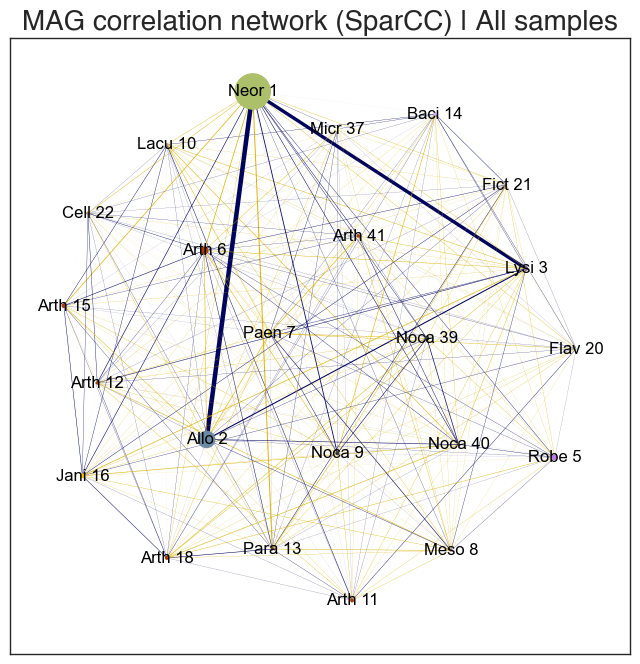

In [12]:
#Plot the correlation network just using all of the values we have.
sns.set_style('white')
mpl.rcParams['font.family'] = 'Helvetica'
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

#Create the network object and store the correlation 'value' as an attribute for each edge
G_cc = nx.from_pandas_edgelist(fastspar_bin_cc_df_melt,source='bin',target='variable',edge_attr=['value'])

edges = G_cc.edges() #ordered list of edges
cc_list = [G_cc[u][v]['value'] for u,v in edges] #correlation value for each edge

#assign each edge a color based on the direction of it's correlation value
edge_color_list_G_cc = [] #store color list here, the graph takes ordered lists of colors for these things
for cc in cc_list: #check each correlation value
    if cc < 0:
        edge_color_list_G_cc.append('xkcd:gold') #negative
    elif cc > 0:
        edge_color_list_G_cc.append('xkcd:dark blue') #positive
    elif cc == 0:
        edge_color_list_G_cc.append('lightgrey') #zero, I don't think we have any exact 0s, but just in case

#Grab the mean abundance of each MAG to use to scale the node sizes
node_sizes = [] #store the node sizes as a list, just like the colors
for node in G_cc.nodes():
    size = all_mean_bin_rel_abund_dict[node] #get mean abundance 'size' from mean abundance dictionary
    node_sizes.append(size*10) #scale the size by a factor of 10, this worked best for plotting

#Make a scaled list of the correlation values to use as edge weights
cc_list_heavy = []
for i in cc_list:
    cc_list_heavy.append(i*10)

#Get the color for each node from the same palette we use for all of the abundance plots
node_color_list = []
for node in G_cc.nodes():
    node_color_list.append(bin_pal[node])

#Rename the nodes here with the better labels (E.g. 'Bin_1' > 'Neor 1')
nx.relabel_nodes(G_cc,bin_label_rename_dict,copy=False)

#Now make a plot to visualize the full correlation network (not yet filtered by significance)
plt.figure(figsize=(8,8))
nx.draw_networkx(G_cc,with_labels=True,pos=G_cc_pos_spring_locked,edge_color=edge_color_list_G_cc,node_color=node_color_list,width=cc_list_heavy,node_size=node_sizes)
plt.title('MAG correlation network (SparCC) | All samples',fontsize=20)
plt.show()

In [13]:
#used a bootstrapping method to calculate p-values for the correlation data
fastspar_pvals_full_set_df = pd.read_csv('./data/fastspar/fastspar_stats/T2_T3_all_bin_abunds_biom/pvalues.tsv',sep='\t')
fastspar_pvals_full_set_df_melt = fastspar_pvals_full_set_df.melt(id_vars=['#OTU ID']).rename({'#OTU ID':'bin'},axis=1) #melt and rename the data to match
fastspar_pvals_full_set_df_melt_filt = fastspar_pvals_full_set_df_melt[fastspar_pvals_full_set_df_melt['value'] <= 0.05].sort_values(by='value') #Subset to only significant p-values (< 0.05) 
#This only leaves 2 edges
fastspar_pvals_full_set_df_melt_filt

,bin,variable,value
9,Bin_2,Bin_1,0.001
13,Bin_3,Bin_1,0.001
207,Bin_1,Bin_2,0.001
299,Bin_1,Bin_3,0.001


In [14]:
def network_filter(df_net,df_p):
    """Function to filter melted fastspar network df based on p-values."""
    df_p['edge'] = df_p['bin'] + '_' + df_p['variable'] #create a common "edge" to subset the network on based on filtered p-values
    df_net['edge'] = df_net['bin'] + '_' + df_net['variable'] #create a common "edge" column
    filt_edges = df_p['edge'].to_list() #prepare list of edges that are under p-value threshold
    df_net_filt = df_net[df_net['edge'].isin(filt_edges)] #Subset df_net with only desired edges

    return df_net_filt

fastspar_bin_cc_df_melt_filt = network_filter(fastspar_bin_cc_df_melt,fastspar_pvals_full_set_df_melt_filt)

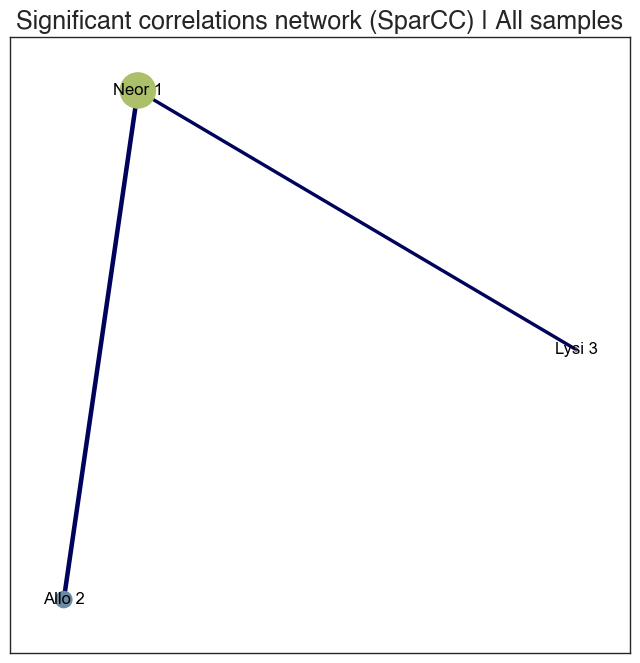

In [15]:
#Remake the plot above, but this time use only the significant edges

G_cc = nx.from_pandas_edgelist(fastspar_bin_cc_df_melt_filt,source='bin',target='variable',edge_attr=['value'])

#See network plot above for details
edges = G_cc.edges()
cc_list = [G_cc[u][v]['value'] for u,v in edges]
edge_color_list_G_cc = []
for cc in cc_list:
    if cc < 0:
        edge_color_list_G_cc.append('xkcd:gold')
    elif cc > 0:
        edge_color_list_G_cc.append('xkcd:dark blue')
    elif cc == 0:
        edge_color_list_G_cc.append('lightgrey')

node_sizes = []
for node in G_cc.nodes():
    size = all_mean_bin_rel_abund_dict[node]
    node_sizes.append(size*10)

cc_list_heavy = []
for i in cc_list:
    cc_list_heavy.append(i*10)

node_color_list = []
for node in G_cc.nodes():
    node_color_list.append(bin_pal[node])

nx.relabel_nodes(G_cc,bin_label_rename_dict,copy=False)

plt.figure(figsize=(8,8))
nx.draw_networkx(G_cc,with_labels=True,pos=G_cc_pos_spring_locked,edge_color=edge_color_list_G_cc,node_color=node_color_list,width=cc_list_heavy,node_size=node_sizes)
plt.title('Significant correlations network (SparCC) | All samples',fontsize=18)
plt.show()

In [16]:
#Now let's read all of those fastspar results back in
fastspar_cond_cc_files = glob.glob('./data/fastspar/*fastspar_correlation.tsv')

#Store each correlation file in a df with a name scraped from the filename
fastspar_df_dict = {}

#Iterate over each file name
for f in fastspar_cond_cc_files:
    n = f.split('/')[3][:-41] #split out the directories and pick the filename, then trim off the end of the file name to keep only the condition details
    fastspar_df_dict[n] = pd.read_csv(f,sep='\t') #add it to the dict

fastspar_df_dict['T2_NLDM_high_NO3'] #example

,#OTU ID,Bin_1,Bin_10,Bin_11,Bin_12,Bin_13,Bin_14,Bin_15,Bin_16,Bin_18,...,Bin_3,Bin_37,Bin_39,Bin_40,Bin_41,Bin_5,Bin_6,Bin_7,Bin_8,Bin_9
0,Bin_1,1.0000,-0.0634,-0.0035,0.1302,-0.0409,0.1067,-0.0936,-0.0675,-0.0264,...,0.5873,-0.0328,-0.0190,-0.0158,-0.0802,0.0461,-0.0270,0.0292,0.0206,-0.0534
1,Bin_10,-0.0634,1.0000,0.0184,0.0401,0.0332,-0.0725,0.0338,-0.0964,-0.0351,...,-0.1375,0.0015,0.0682,-0.0414,0.0517,0.0251,-0.0503,-0.0625,0.0108,-0.0258
2,Bin_11,-0.0035,0.0184,1.0000,-0.0508,-0.0048,0.0438,-0.0340,0.0210,0.0466,...,-0.0610,0.0892,-0.0987,-0.0465,-0.0007,-0.0549,0.0432,-0.0714,0.0227,-0.0085
3,Bin_12,0.1302,0.0401,-0.0508,1.0000,-0.0945,0.0484,-0.0675,0.0715,-0.0399,...,-0.0213,-0.0564,-0.0805,-0.0270,0.0606,0.0203,-0.0037,-0.0501,-0.1331,-0.0536
4,Bin_13,-0.0409,0.0332,-0.0048,-0.0945,1.0000,0.0338,0.0232,-0.0068,-0.0213,...,-0.0772,0.0890,0.0594,0.0252,-0.0670,0.0014,0.0471,0.0318,-0.1131,0.0036
5,Bin_14,0.1067,-0.0725,0.0438,0.0484,0.0338,1.0000,-0.0622,0.0381,0.0121,...,-0.0138,-0.1098,0.0263,0.0083,0.0479,0.0045,0.0091,0.0888,-0.1768,-0.0086
6,Bin_15,-0.0936,0.0338,-0.0340,-0.0675,0.0232,-0.0622,1.0000,0.0101,-0.0301,...,-0.0671,0.1142,-0.0012,-0.0088,0.0649,0.0056,0.0407,0.0310,-0.0459,-0.0233
7,Bin_16,-0.0675,-0.0964,0.0210,0.0715,-0.0068,0.0381,0.0101,1.0000,0.0409,...,-0.1012,-0.0064,0.0691,0.0349,0.0478,-0.0414,0.1312,0.0145,-0.0308,-0.0031
8,Bin_18,-0.0264,-0.0351,0.0466,-0.0399,-0.0213,0.0121,-0.0301,0.0409,1.0000,...,-0.0470,0.0043,-0.0450,-0.0150,0.0468,0.0370,0.1155,-0.1006,0.0300,-0.0108
9,Bin_2,0.6964,-0.0694,0.0067,0.1573,-0.0113,-0.1151,-0.0958,-0.0579,0.0242,...,0.4445,0.0052,-0.0017,-0.0013,-0.0473,0.0313,0.0181,-0.1049,0.1151,-0.0079


In [17]:
#Repeat the above procedure to get the corresponding p-value matrices
fastspar_pval_files = glob.glob('./data/fastspar/fastspar_stats/*_biom/pvalues.tsv')

#Store p-value matrices in a dict
fastspar_p_dict = {}

for f in fastspar_pval_files:
    n = n = f.split('/')[4][:-16]
    fastspar_p_dict[n] = pd.read_csv(f,sep='\t') #add it to the dict

fastspar_p_dict['T2_NLDM_high_NO3'] #example

,#OTU ID,Bin_1,Bin_10,Bin_11,Bin_12,Bin_13,Bin_14,Bin_15,Bin_16,Bin_18,...,Bin_3,Bin_37,Bin_39,Bin_40,Bin_41,Bin_5,Bin_6,Bin_7,Bin_8,Bin_9
0,Bin_1,1.0000,0.6234,0.9810,0.3437,0.7602,0.5145,0.4306,0.5844,0.8322,...,0.0030,0.8012,0.8801,0.8901,0.5345,0.7542,0.8312,0.8561,0.8891,0.6803
1,Bin_10,0.6234,1.0000,0.8761,0.8102,0.8306,0.7153,0.7862,0.4935,0.8382,...,0.2737,0.9940,0.4765,0.7872,0.6384,0.8621,0.8791,0.6324,0.9660,0.8372
2,Bin_11,0.9810,0.8761,1.0000,0.6424,0.9730,0.8302,0.6883,0.9141,0.6923,...,0.6533,0.3976,0.3596,0.7493,0.9970,0.6004,0.7003,0.6743,0.8901,0.9341
3,Bin_12,0.3437,0.8102,0.6424,1.0000,0.5864,0.7023,0.6883,0.8102,0.7353,...,0.8721,0.6384,0.5495,0.8492,0.5954,0.8561,0.9680,0.7183,0.3467,0.7273
4,Bin_13,0.7602,0.8306,0.9730,0.5864,1.0000,0.7952,0.8791,0.9580,0.8791,...,0.5455,0.4595,0.4785,0.8422,0.6843,0.9890,0.6354,0.7882,0.2917,0.9710
5,Bin_14,0.5145,0.7153,0.8302,0.7023,0.7952,1.0000,0.6573,0.7812,0.9640,...,0.9131,0.3646,0.8521,0.9461,0.6953,0.9840,0.9431,0.5115,0.2378,0.9421
6,Bin_15,0.4306,0.7862,0.6883,0.6883,0.8791,0.6573,1.0000,0.9241,0.8242,...,0.5874,0.2917,0.9970,0.9540,0.7093,0.9750,0.8501,0.7982,0.8002,0.8182
7,Bin_16,0.5844,0.4935,0.9141,0.8102,0.9580,0.7812,0.9241,1.0000,0.7682,...,0.4046,0.9500,0.4935,0.8142,0.8362,0.7213,0.5644,0.9061,0.8541,0.9800
8,Bin_18,0.8322,0.8382,0.6923,0.7353,0.8791,0.9640,0.8242,0.7682,1.0000,...,0.7343,0.9830,0.7313,0.8841,0.8002,0.7802,0.2028,0.5005,0.8452,0.9131
9,Bin_2,0.0010,0.5694,0.9580,0.2547,0.9500,0.4625,0.4605,0.6454,0.8432,...,0.0180,0.9810,0.9910,0.9970,0.6793,0.8242,0.8781,0.5115,0.4456,0.9560


In [18]:
def fastspar_network_filt_format(condition):
    
    """Function to create a filtered network dataframe for each condition"""

    #Start by importing and melting the network df
    df_net = fastspar_df_dict[condition]
    df_net_melt = df_net.melt(id_vars=['#OTU ID']).rename({'#OTU ID':'bin','value':condition},axis=1) #Melt and rename the columns; the 'value'/condition column will be the correlation value for plotting later

    #Import and melt the p-value matrices
    df_p = fastspar_p_dict[condition]
    df_p_melt = df_p.melt(id_vars=['#OTU ID']).rename({'#OTU ID':'bin','value':condition},axis=1) #Melt and rename identical to the above

    #Create an 'edge' column in each to subset the network df
    df_net_melt['edge'] = df_net_melt['bin'] + '_' + df_net_melt['variable']
    df_p_melt['edge'] = df_p_melt['bin'] + '_' + df_p_melt['variable']

    #Now filter the network df using the edges that are significant
    df_p_melt_filt = df_p_melt[df_p_melt[condition] <= 0.05] #Only keep the rows with significant p-values
    df_net_melt_filt = df_net_melt[df_net_melt['edge'].isin(df_p_melt_filt['edge'].to_list())] #Only keep the network edges that are significant

    #Each edge is duplicated here and needs to be de-duplicated
    #Use this numpy sort and filtering method
    df_net_melt_filt_dedup = df_net_melt_filt[~pd.DataFrame(np.sort(df_net_melt_filt[['bin','variable']], axis=1), index=df_net_melt_filt.index).duplicated()]
    df_net_melt_filt_dedup = df_net_melt_filt_dedup[df_net_melt_filt_dedup['bin'].isin(good_bin_list) & df_net_melt_filt_dedup['variable'].isin(good_bin_list)]

    return df_net_melt_filt_dedup

fastspar_network_filt_format('T2_T3_all')

,bin,variable,T2_T3_all,edge
9,Bin_2,Bin_1,0.3255,Bin_2_Bin_1
13,Bin_3,Bin_1,0.2442,Bin_3_Bin_1


In [19]:
#now, let's use the function above to create a dictionary of the p-value filtered fastspar (SparCC) networks
filtered_fastspar_df_dict = {}
for condition in fastspar_df_dict.keys():
    df_filt = fastspar_network_filt_format(condition)
    filtered_fastspar_df_dict[condition] = df_filt

filtered_fastspar_df_dict['T3_acetate'] #example

,bin,variable,T3_acetate,edge
51,Bin_14,Bin_11,-0.0031,Bin_14_Bin_11
56,Bin_20,Bin_11,0.0044,Bin_20_Bin_11
57,Bin_21,Bin_11,0.0015,Bin_21_Bin_11
59,Bin_3,Bin_11,0.0139,Bin_3_Bin_11
125,Bin_20,Bin_14,0.0528,Bin_20_Bin_14
126,Bin_21,Bin_14,-0.0147,Bin_21_Bin_14
128,Bin_3,Bin_14,-0.0090,Bin_3_Bin_14
241,Bin_21,Bin_20,-0.0223,Bin_21_Bin_20
243,Bin_3,Bin_20,0.0242,Bin_3_Bin_20
266,Bin_3,Bin_21,0.0263,Bin_3_Bin_21


In [20]:
#Need to create dictionary of bin abundances by condition, so we don't have to recalculate for every plot
#Use this to scale the nodes for the network for each condition that way each MAG is represented by its mean abundance in that condition
bin_abunds_by_condition_dict = {}
for condition in fastspar_df_dict.keys():
    if condition == 'All':
        df_cond_abunds = bin_abunds_df_biom
        df_cond_abunds_rel = df_cond_abunds.div(df_cond_abunds.sum()).mul(100) #make it relative abundance data to match the rest of the analyses
    else:
        df_cond_abunds = pd.read_csv(f'../20250106_encom_all_combined/20260213_fastspar/{condition}_bin_abunds_biom.txt',sep='\t',index_col=0)
        df_cond_abunds_rel = df_cond_abunds.div(df_cond_abunds.sum()).mul(100) #make it relative abundance data to match the rest of the analyses
    mean_covs = df_cond_abunds_rel.reindex(bin_order).T.mean().to_list()
    size_dict = {}
    for i in range(len(bin_order)):
        size_dict[bin_order[i]] = mean_covs[i]
    bin_abunds_by_condition_dict[condition] = size_dict

bin_abunds_by_condition_dict['All'] = bin_abunds_by_condition_dict['T2_T3_all'] #just to keep the 'All' key for later
bin_abunds_by_condition_dict

{'T3_acetate_pH7': {'Bin_1': 89.33532027999027,
  'Bin_2': 4.3654752322552834,
  'Bin_3': 0.0,
  'Bin_4': nan,
  'Bin_5': 0.018985587105896404,
  'Bin_6': 0.009282345848558008,
  'Bin_7': 0.005690711614110818,
  'Bin_8': 0.0,
  'Bin_9': 4.077384093042705,
  'Bin_10': 0.036107497492836094,
  'Bin_11': 0.0,
  'Bin_12': 0.0030484176468745672,
  'Bin_13': 0.0,
  'Bin_14': 0.0,
  'Bin_15': 0.0,
  'Bin_16': 0.3191746273400381,
  'Bin_17': nan,
  'Bin_18': 0.0,
  'Bin_19': nan,
  'Bin_20': 0.0,
  'Bin_21': 0.0,
  'Bin_22': 0.03399337838041803,
  'Bin_23': nan,
  'Bin_24': nan,
  'Bin_25': nan,
  'Bin_26': nan,
  'Bin_27': nan,
  'Bin_28': nan,
  'Bin_29': nan,
  'Bin_30': nan,
  'Bin_31': nan,
  'Bin_32': nan,
  'Bin_33': nan,
  'Bin_34': nan,
  'Bin_35': nan,
  'Bin_36': nan,
  'Bin_37': 0.00037318365666294653,
  'Bin_38': nan,
  'Bin_39': 1.4002077052160335,
  'Bin_40': 0.39495694041030827,
  'Bin_41': 0.0},
 'T3_lactate': {'Bin_1': 54.04816616559407,
  'Bin_2': 41.68790748968064,
  'Bin_3'

In [21]:
#total number of possible interactions between the MAGs
print('Total possible correlations:',(len(good_bin_list)**2 - len(good_bin_list))/2) #square for pairwise MAG comparisons, remove self-self edges, remove remaining duplicates

Total possible correlations: 253.0


T3_acetate_pH7 		 44
T3_lactate 		 7
T3_lactate_pH4 		 22
T3_citrate_pH7 		 41
T3_pyruvate_low_NO3 		 25
T3_pyruvate 		 9
T3_lactate_pH7 		 52
T3_citrate_high_NO3 		 44
T3_citrate_pH4 		 28
T2_NLDM_high_NO3 		 4
T2_NLDM_pH6 		 2
T3_acetate_pH4 		 28
T3_lactate_low_NO3 		 34
T3_acetate_low_NO3 		 41
T3_pyruvate_high_NO3 		 29
T3_citrate_low_NO3 		 36
T3_citrate 		 6
T3_glucose_pH7 		 17
T3_lactate_high_NO3 		 22
T3_pyruvate_pH7 		 60
T2_T3_all 		 2
T3_acetate_high_NO3 		 69
T2_NLDM 		 3
T2_NLDM_pH4 		 0
T3_glucose 		 7
T3_pyruvate_pH4 		 28
T3_glucose_low_NO3 		 22
T2_NLDM_pH7 		 3
T3_glucose_high_NO3 		 35
T3_glucose_pH4 		 28
T2_NLDM_low_NO3 		 1
T3_acetate 		 10


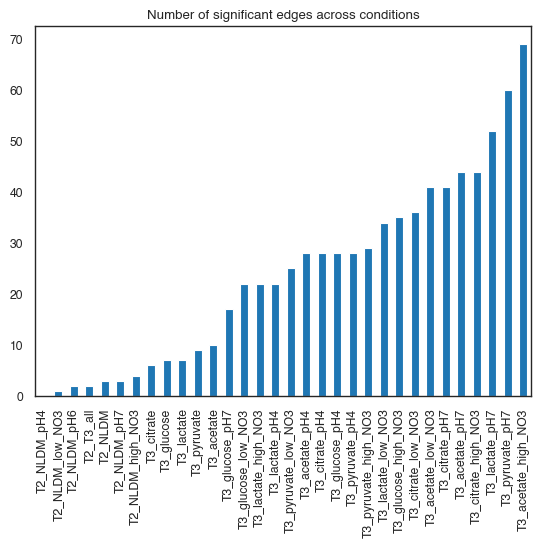

In [22]:
#Out of curiosity, gathering data to see how many significant edges are found for each condition
n_edges = []
for k,v in filtered_fastspar_df_dict.items():
    print(k,'\t\t',len(v)) #print so we can read exact values
    n_edges.append((len(v),k)) #save tuple of how many edges are found for each condition

n_edges = sorted(n_edges) #sort both by the count value
counts = [i[0] for i in n_edges] #extract ordered list of counts
labels = [i[1] for i in n_edges] #extract ordered list of labels

pd.Series(counts).plot(kind='bar') #plot the sorted counts
plt.xticks(ticks=range(len(counts)),labels=labels) #add the labels
plt.title('Number of significant edges across conditions')
plt.show()

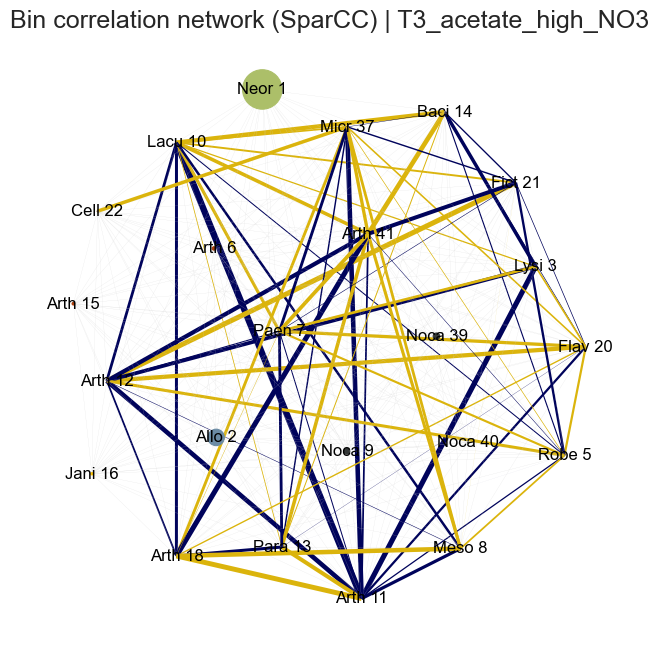

In [23]:
#Let's create some plots that show the full network but subset the colored edges and nodes to those that are significant
def fastspar_sig_good_bin_network_plotter(condition,ax=None):
    """Plot significant correlation network in context of full network"""
    
    df_net = fastspar_df_dict[condition].melt(id_vars=['#OTU ID']).rename({'#OTU ID':'bin','value':condition},axis=1) #create a conditional network df with all edges
    df_net = df_net[df_net['bin'] != df_net['variable']] #remove self edges
    df_net['edge'] = df_net['bin'] + '_' + df_net['variable'] #create an edge variable for filtering

    #Filter the network to only include the nearly complete bins
    df_net = df_net[df_net['bin'].isin(good_bin_list)].loc[df_net['variable'].isin(good_bin_list)]

    #Start by creating a networkx object from the filtered network df
    G_cc = nx.from_pandas_edgelist(df_net,source='bin',target='variable',edge_attr=[condition,'edge'])
    edges = G_cc.edges() #Extract edges for annotating the plot
    cc_list = [G_cc[u][v][condition] for u,v in edges] #List of correlation values

    sig_edges_list = filtered_fastspar_df_dict[condition]['edge'].to_list()

    G_edge_list = [G_cc[u][v]['edge'] for u,v in edges]

    edge_color_list_G_cc = [] #Create list of colors for edges based on significance and correlation values
    edge_width_list_G_cc = []
    for i in range(len(G_edge_list)):
        edge = G_edge_list[i]
        alt_edge_parts_list = G_edge_list[i].split('_')
        alt_edge = '_'.join([alt_edge_parts_list[2],alt_edge_parts_list[3],alt_edge_parts_list[0],alt_edge_parts_list[1]])

        if edge in sig_edges_list or alt_edge in sig_edges_list:
            cc = cc_list[i]
            edge_width_list_G_cc.append(cc*20)
            if cc < 0: #Negative correlations are red
                edge_color_list_G_cc.append('xkcd:gold')
            elif cc > 0: #Positive correlations are green
                edge_color_list_G_cc.append('xkcd:dark blue')
            elif cc == 0: #Neutral correlations are black; I don't think this happens...
                edge_color_list_G_cc.append('lightgrey')
        elif edge not in sig_edges_list or alt_edge not in sig_edges_list:
            edge_width_list_G_cc.append(0.1)
            edge_color_list_G_cc.append('lightgrey')

    size_dict = bin_abunds_by_condition_dict[condition] #Get the mean abundance for each bin for this condition to size the nodes

    node_sizes = []
    for node in G_cc.nodes():
        size = size_dict[node] #Determine size for each bin based on mean in the condition
        node_sizes.append(size*10) #Scale the size up for plotting aesthetics

    node_color_list = [] #Color the nodes based on the previously identified palette for each bin by its genus
    for node in G_cc.nodes():
        node_color_list.append(bin_pal[node])

    #relabel the nodes with names that match the anvio figure
    nx.relabel_nodes(G_cc,bin_label_rename_dict,copy=False)

    #Now, let's create the network plots
    sns.set_style('white')

    if ax == None: #The ax option is here so that the networks can be looped and plotted in subplots
        plt.figure(figsize=(8,8)) #Set the size
        #Draw the network; use the original positions for the first full unfiltered network
        nx.draw_networkx(G_cc,with_labels=True,pos=G_cc_pos_spring_locked,edge_color=edge_color_list_G_cc,node_color=node_color_list,width=edge_width_list_G_cc,node_size=node_sizes)
        plt.title(f'Bin correlation network (SparCC) | {condition}',fontsize=18)
        plt.box(False)
        plt.show()

    elif ax != None: #This option is to make plots that stand alone
        nx.draw_networkx(G_cc,with_labels=True,font_size=6,pos=G_cc_pos_spring_locked,edge_color=edge_color_list_G_cc,node_color=node_color_list,width=[i/2.5 for i in edge_width_list_G_cc],node_size=[i/2.5 for i in node_sizes],ax=ax)
        ax.set_frame_on(False)
        #Don't show the plots so that it doesn't end the subplot early

fastspar_sig_good_bin_network_plotter('T3_acetate_high_NO3')

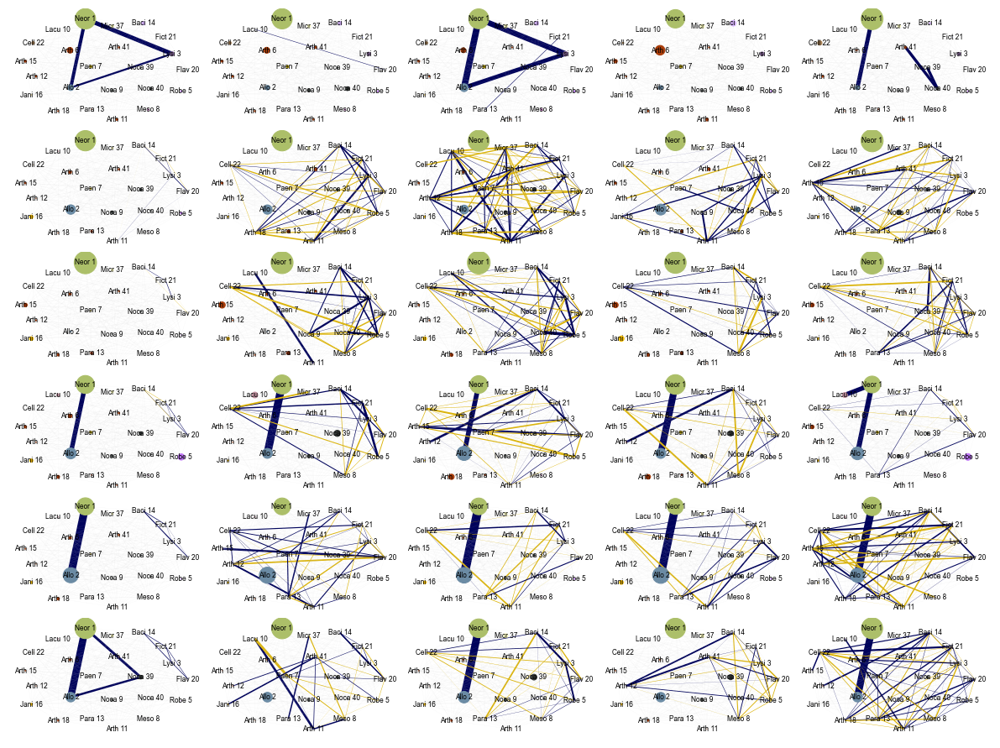

In [24]:
#Ordered list of conditions for plotting matrix of correlation networks; Figure 3A in the manuscript
corr_conds = ['T2_NLDM', 'T2_NLDM_low_NO3', 'T2_NLDM_high_NO3', 'T2_NLDM_pH4', 'T2_NLDM_pH7',
 'T3_acetate', 'T3_acetate_low_NO3', 'T3_acetate_high_NO3', 'T3_acetate_pH4', 'T3_acetate_pH7',
 'T3_citrate', 'T3_citrate_low_NO3', 'T3_citrate_high_NO3', 'T3_citrate_pH4', 'T3_citrate_pH7',
 'T3_glucose', 'T3_glucose_low_NO3', 'T3_glucose_high_NO3', 'T3_glucose_pH4', 'T3_glucose_pH7',
 'T3_lactate', 'T3_lactate_low_NO3', 'T3_lactate_high_NO3', 'T3_lactate_pH4', 'T3_lactate_pH7',
 'T3_pyruvate', 'T3_pyruvate_low_NO3', 'T3_pyruvate_high_NO3', 'T3_pyruvate_pH4', 'T3_pyruvate_pH7']

#Set up the subplot grid to add the networks
fig,ax = plt.subplots(figsize=(12,9),nrows=6,ncols=5)

#Start counters for rows and columns so we can fill the subplot grid
n_rows=0
n_cols=0
for condition in corr_conds:
    fastspar_sig_good_bin_network_plotter(condition,ax=ax[n_rows,n_cols]) #use the variables for subplot mapping
    n_cols += 1 #first step to the next column
    if n_cols > 4: #Until the end of the row is reached
        n_rows += 1 #Move to the next row
        n_cols = 0 #reset the column

plt.tight_layout(h_pad=0,w_pad=0) #keep the plots close to each other

#plt.savefig('../figs/corr_net_matrix/correlation_network_matrix.png',dpi=300,bbox_inches='tight')
plt.show()

In [25]:
#Get counts of total numbers of significant edges for different carbon sources
single_C_k = ['T3_acetate','T3_citrate','T3_glucose','T3_lactate','T3_pyruvate']

NLDM_n_edges = []
all_SGW_n_edges = []
SGW_n_edges = {}

for k,v in filtered_fastspar_df_dict.items():
    if 'NLDM' in k:
        NLDM_n_edges.append(len(v)) #list number of edges for each NLDM condition
    elif k in single_C_k and 'T2_T3' not in k: #only keeping number of edges here for the full network for each C source (first column of the grid above)
        SGW_n_edges[k] = len(v)
    elif 'T3' in k and 'T2_T3' not in k: #Get the number of edges for the other single C source conditions
        all_SGW_n_edges.append(len(v))
    
#Print out the counts for our information.
print(f'Number of NLDM splits: {len(NLDM_n_edges)}')
print(f'Min number of sig edges for NLDM networks: {np.array(NLDM_n_edges).min()}')
print(f'Max number of sig edges for NLDM networks: {np.array(NLDM_n_edges).max()}\n')

for k in single_C_k:
    print(f'Number of sig edges in all {k} sample network: {SGW_n_edges[k]}')

print(f'\nNumber of single C sub condition splits: {len(all_SGW_n_edges)}')
print(f'Min number of sig edges for single C sub condition splits: {np.array(all_SGW_n_edges).min()}')
print(f'Max number of sig edges for single C sub condition splits: {np.array(all_SGW_n_edges).max()}')

Number of NLDM splits: 6
Min number of sig edges for NLDM networks: 0
Max number of sig edges for NLDM networks: 4

Number of sig edges in all T3_acetate sample network: 10
Number of sig edges in all T3_citrate sample network: 6
Number of sig edges in all T3_glucose sample network: 7
Number of sig edges in all T3_lactate sample network: 7
Number of sig edges in all T3_pyruvate sample network: 9

Number of single C sub condition splits: 20
Min number of sig edges for single C sub condition splits: 17
Max number of sig edges for single C sub condition splits: 69


In [26]:
#Now, separate out number of positive and negative edges for all subconditional splits
sub_conds = sorted(filtered_fastspar_df_dict.keys()) #sorted list of all the sub conditions

#Lists to store counts
total_single_C_edges = []
total_C_subcond_edges = []

for k in sub_conds:
    v = filtered_fastspar_df_dict[k]
    if 'T3' in k and 'T2' not in k: #Just selecting the single C sub conditions
        pos_edges = [] #Sort the positive and negative correlation values into lists
        neg_edges = []
        corr_values = v[k] #This seems like we're going in circles, but don't worry about it. It works.
        for i in corr_values:
            if i > 0:
                pos_edges.append(i) #Keep the values for calculations later
            elif i < 0:
                neg_edges.append(i)
        if k in single_C_k:
            total_single_C_edges.append(len(corr_values)) #total number of values for all samples for each C source
        elif k not in single_C_k:
            total_C_subcond_edges.append(len(corr_values)) #total number of values for sub conditions
        
        #Print out the counts here
        print(f'Total edges in {k}: {len(corr_values)}')
        print(f'Positive edges in {k}: {len(pos_edges)}')
        print(f'Negative edges in {k}: {len(neg_edges)}\n')



Total edges in T3_acetate: 10
Positive edges in T3_acetate: 6
Negative edges in T3_acetate: 4

Total edges in T3_acetate_high_NO3: 69
Positive edges in T3_acetate_high_NO3: 36
Negative edges in T3_acetate_high_NO3: 33

Total edges in T3_acetate_low_NO3: 41
Positive edges in T3_acetate_low_NO3: 17
Negative edges in T3_acetate_low_NO3: 24

Total edges in T3_acetate_pH4: 28
Positive edges in T3_acetate_pH4: 17
Negative edges in T3_acetate_pH4: 11

Total edges in T3_acetate_pH7: 44
Positive edges in T3_acetate_pH7: 22
Negative edges in T3_acetate_pH7: 22

Total edges in T3_citrate: 6
Positive edges in T3_citrate: 2
Negative edges in T3_citrate: 4

Total edges in T3_citrate_high_NO3: 44
Positive edges in T3_citrate_high_NO3: 27
Negative edges in T3_citrate_high_NO3: 17

Total edges in T3_citrate_low_NO3: 36
Positive edges in T3_citrate_low_NO3: 19
Negative edges in T3_citrate_low_NO3: 17

Total edges in T3_citrate_pH4: 28
Positive edges in T3_citrate_pH4: 16
Negative edges in T3_citrate_pH4

In [27]:
print(f'Average n edges in single C splits = {np.array(total_single_C_edges).mean()} | range = {np.array(total_single_C_edges).min()} – {np.array(total_single_C_edges).max()}')
print(f'Average n edges in single C sub condition splits = {np.array(total_C_subcond_edges).mean()} | range = {np.array(total_C_subcond_edges).min()} – {np.array(total_C_subcond_edges).max()}')
print('All C samples vs subconditions',ttest_ind(total_single_C_edges,total_C_subcond_edges,equal_var=False)) #run a Wald's test since the number of values is different for these lists

Average n edges in single C splits = 7.8 | range = 6 – 10
Average n edges in single C sub condition splits = 35.25 | range = 17 – 69
All C samples vs subconditions TtestResult(statistic=np.float64(-8.829307430762128), pvalue=np.float64(1.6575220604095185e-08), df=np.float64(20.96641421844089))


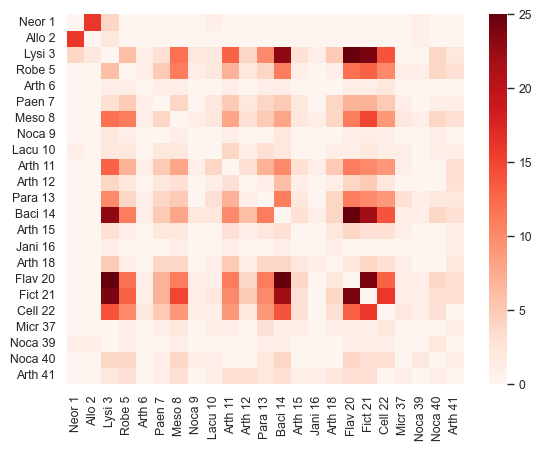

In [28]:
#Quick check to see how many times each MAG is significantly correlated with each other MAG

MAG_MAG_n_corr_dict = {} #Store counts of correlations between each MAG here

#Loop over each MAG pairwise
for i in better_bin_list:
    i_sig_corrs = {} #Store num correlations of MAG i with each MAG j
    for j in better_bin_list:
        i_sig_corrs[j] = 0 #initialize the count for MAG j so we can step it up as we iterate

    for cond in sub_conds: #loop over each subcondition
        cond_df = filtered_fastspar_df_dict[cond]
        cond_df = cond_df[cond_df['bin'].isin([i]) | cond_df['variable'].isin([i])] #check each edge that has MAG i
        cond_i_sig_corrs = set(cond_df['bin'].to_list() + cond_df['variable'].to_list()) #this is a set of all MAGs for this subcondition that are correlated with MAG i
        for j in better_bin_list: #now check each MAG j for correlation with MAG i
            if j != i: #no self!
                if j in cond_i_sig_corrs:
                    i_sig_corrs[j] += 1 #count each time j shows up
    MAG_MAG_n_corr_dict[i] = i_sig_corrs #Now store counts for each MAG j related to each MAG i

MAG_MAG_n_corr_df = pd.DataFrame(MAG_MAG_n_corr_dict).rename(bin_label_rename_dict,axis=1).rename(bin_label_rename_dict,axis=0) #store the counts and rename the axes to match

#Visualize as a heatmap
sns.heatmap(MAG_MAG_n_corr_df,cmap='Reds')
plt.show()

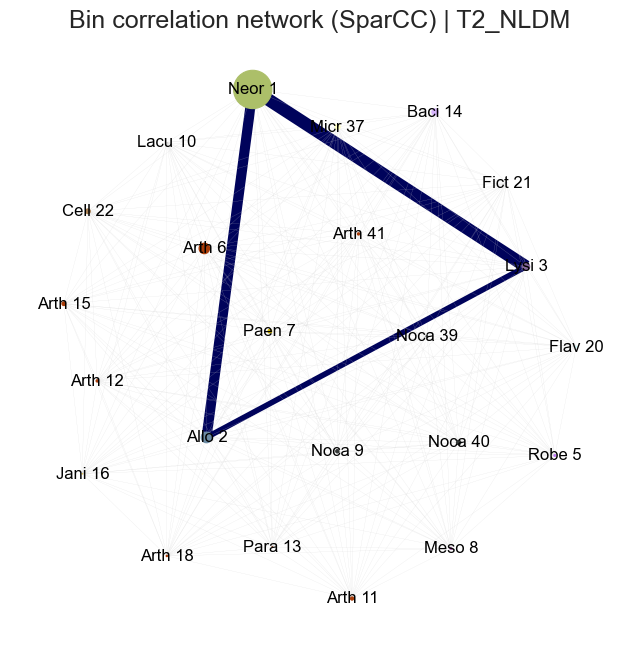

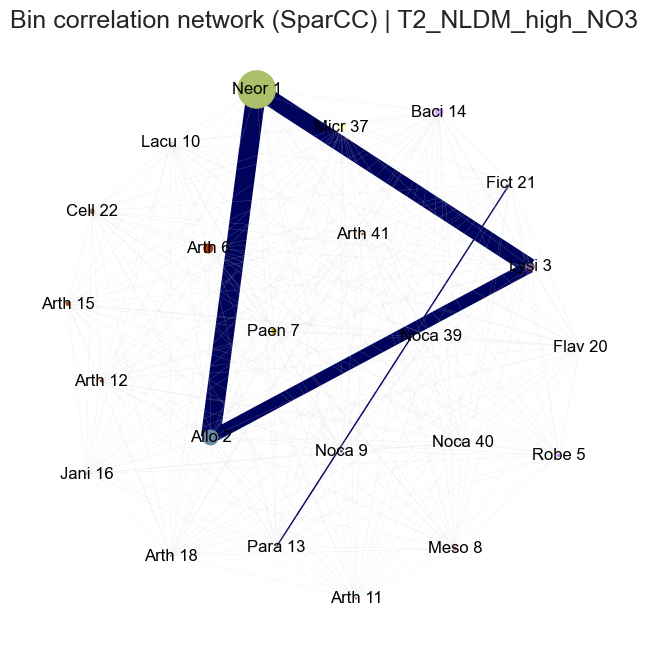

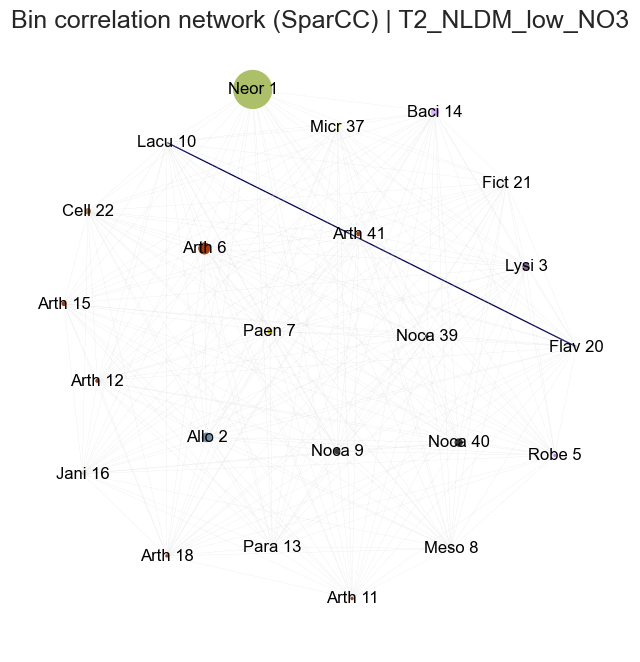

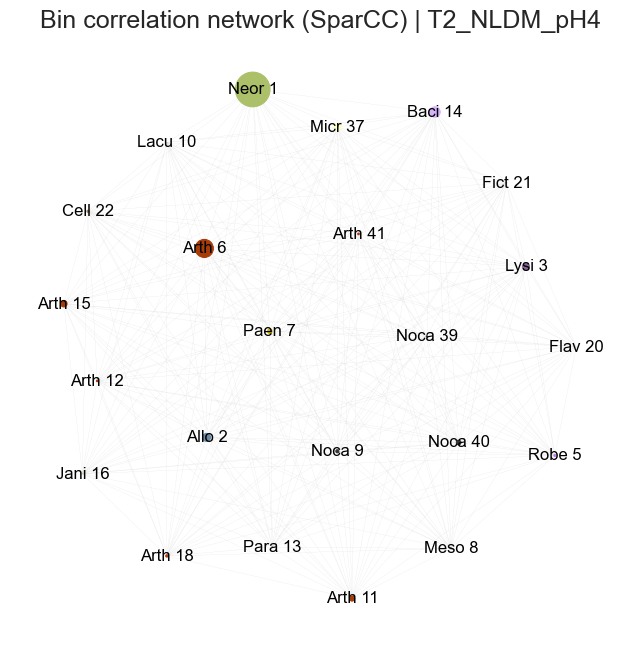

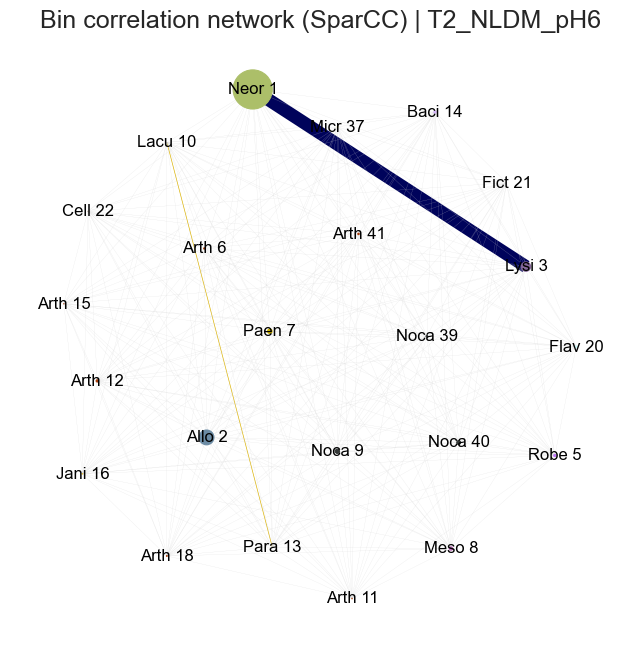

...

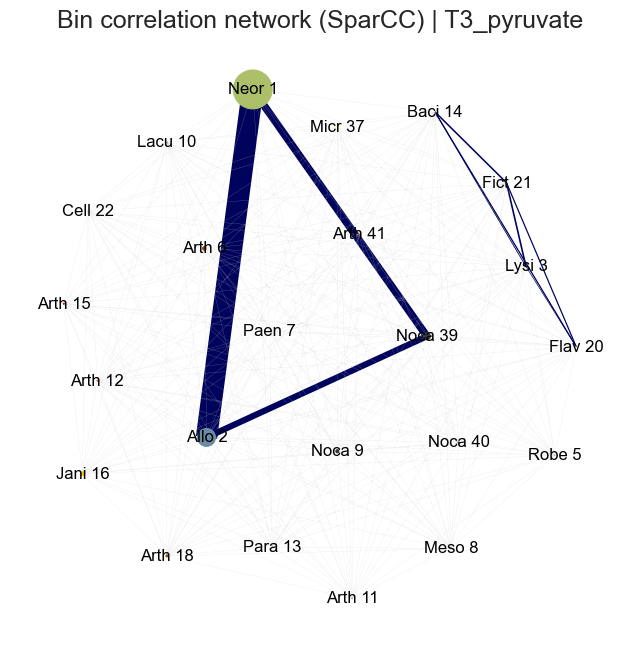

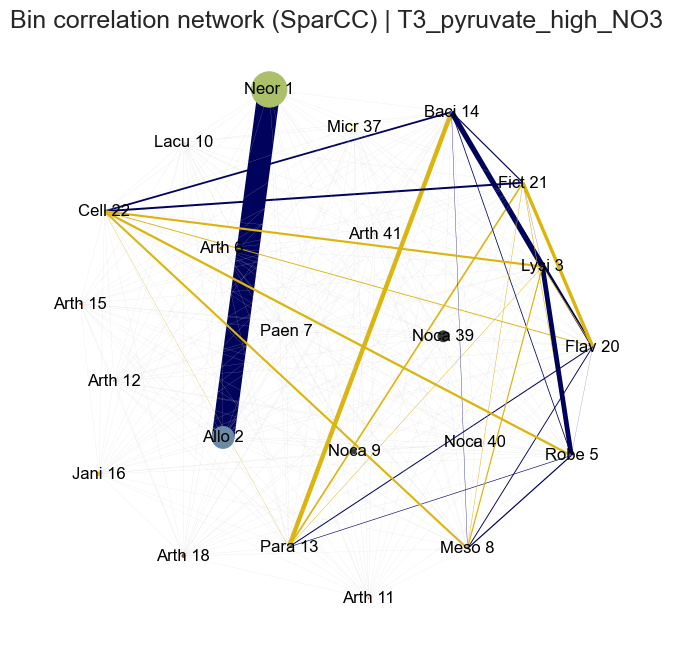

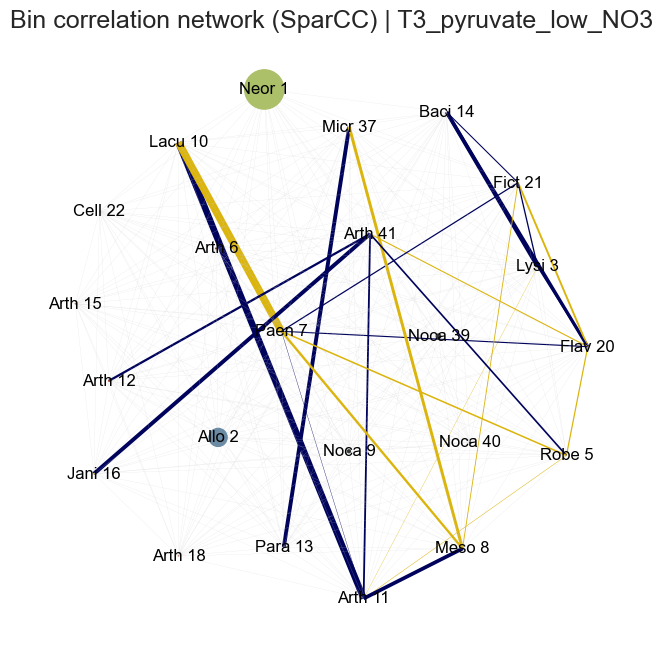

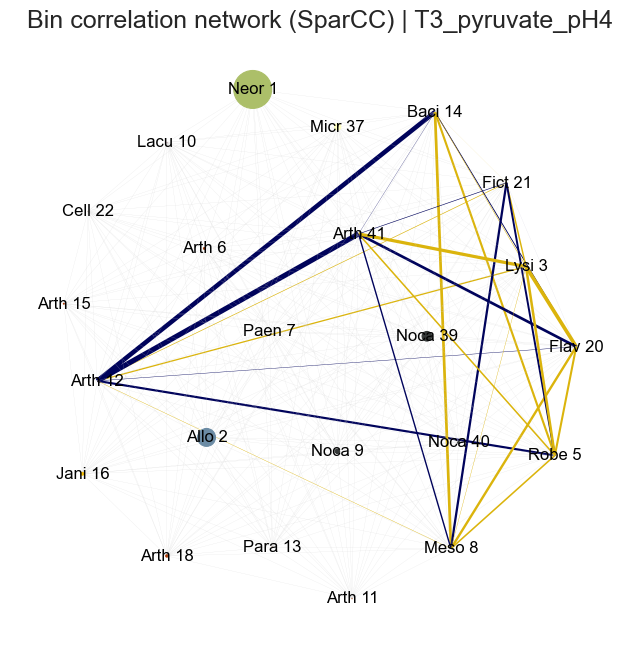

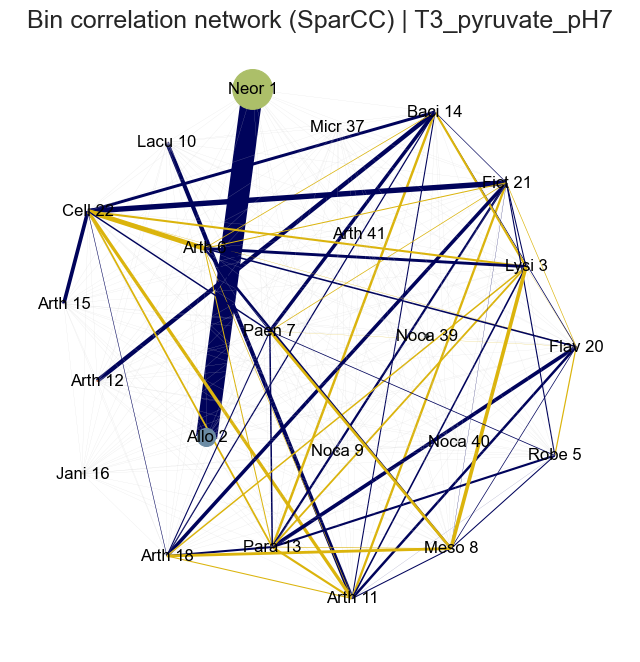

In [29]:
#Plot the network for each condition individually for a closer look. 
for condition in sorted(filtered_fastspar_df_dict.keys()):
    fastspar_sig_good_bin_network_plotter(condition)

# Link community analysis

In [30]:
#Rather than just feeding in the all correlations matrix (T2_T3_all only has 3 significant correlations), try building a matrix based off of significant correlations across conditions
#then run link community clustering on it

sig_bin_correlations_across_conds_dict = {} #store the mean of n sig correlations between bins here

for b_i in good_bin_list: #iterate over each bin_i
    b_ij_corrs = np.array([0]*len(good_bin_list)) #create a dummy array to add n sig correlations for each bin_j; this saves a loop vs. last time I did this
    for condition,df in sorted(filtered_fastspar_df_dict.items()): #iterate over each condition's significant correlation network df
        b_ij_cond_corrs = [] #count the number of significant correlations each bin_j has with bin_i
        df_cond = df.copy() #create a df copy so we don't alter the original on accident
        df_cond_b = df_cond[df_cond['bin'].isin([b_i])|df_cond['variable'].isin([b_i])] #subset the df_cond so we only look at edges with bin_i ('bin'; 'variable' is bin_j)
        sig_b_correlations = df_cond_b['bin'].to_list() + df_cond_b['variable'].to_list() #list all bins in the significant edges for this condition
        sig_b_correlations = [i for i in sig_b_correlations if i != b_i] #get rid of bin_i in the list

        for b_j in good_bin_list: #iterate over each bin_j now to check if correlation for this condition is significant
            if b_j in sig_b_correlations:
                correlation_df = df_cond_b[df_cond_b['bin'].isin([b_i,b_j])&df_cond_b['variable'].isin([b_i,b_j])] #the correlation value column is named after the condition; subset to the b_ij edge
                correlation = correlation_df[condition].iloc[0] #grab the value from the df
                b_ij_cond_corrs.append(correlation) #add it to our sum array
            elif b_j not in sig_b_correlations: #if the edge is not significant for a condition, make the value 0
                b_ij_cond_corrs.append(0) #If the bins are not significantly correlated, set value to 0; this is a potential bias point, ameliorating the mean with 0s, but the clustering algo doesn't like nans

        b_ij_cond_corrs = np.array(b_ij_cond_corrs) #after adding corr values for a condition, make it into an array so it can be added to the total
        b_ij_corrs = b_ij_corrs + b_ij_cond_corrs #add this conditions values to the total array
    
    #After all conditions have been parsed, get the average correlation value over all conditions
    b_ij_corrs_norm = b_ij_corrs / len(filtered_fastspar_df_dict) #divide the number of interaction conditions by the total possible number of conditions to get the mean

    sig_bin_correlations_across_conds_dict[b_i] = b_ij_corrs_norm #store the array in a dictionary to be made into a dataframe

#Create a dataframe for each b_ij edge and melt it (and do a little renaming to make it make more sense for export)
sig_bin_correlations_across_conds_df = pd.DataFrame(sig_bin_correlations_across_conds_dict,index=good_bin_list).reset_index(names='bin_i').melt(id_vars='bin_i').rename({'variable':'bin_j','value':'mean_correlations'},axis=1)
sig_bin_correlations_across_conds_df = sig_bin_correlations_across_conds_df[sig_bin_correlations_across_conds_df['bin_i']!=sig_bin_correlations_across_conds_df['bin_j']] #drop b_ii correlation edges; final mean correlation df

sig_bin_correlations_across_conds_df[sig_bin_correlations_across_conds_df['bin_i'].isin(['Bin_1','Bin_2'])&sig_bin_correlations_across_conds_df['bin_j'].isin(['Bin_1','Bin_2'])] #Check to see the mean correlation of bins 1 and 2

,bin_i,bin_j,mean_correlations
9,Bin_2,Bin_1,0.334959
207,Bin_1,Bin_2,0.334959


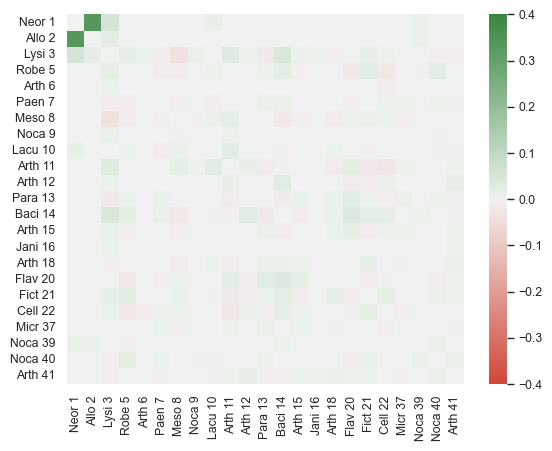

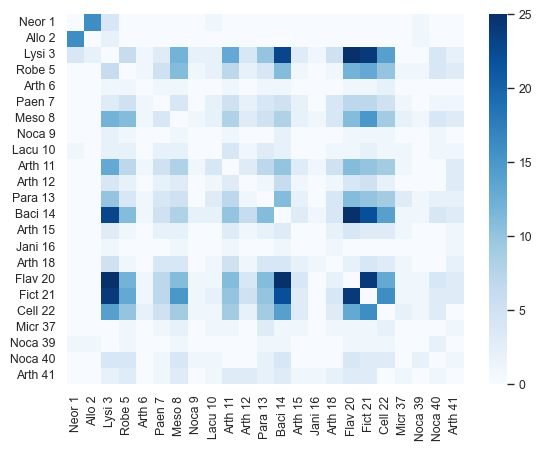

In [31]:
MAG_MAG_mean_corr_df = pd.DataFrame(sig_bin_correlations_across_conds_dict,index=good_bin_list).reindex(better_bin_list) #Making a square form of the mean correlations df
MAG_MAG_mean_corr_df = MAG_MAG_mean_corr_df[better_bin_list].rename(bin_label_rename_dict,axis=1).rename(bin_label_rename_dict,axis=0) #renaming the axes with better labels

#plot the mean correlations
sns.heatmap(MAG_MAG_mean_corr_df,cmap=sns.diverging_palette(15, 130, as_cmap=True),vmin=-0.4,vmax=0.4)
plt.show()

#and plot the number of correlations between each MAG (from above)
sns.heatmap(MAG_MAG_n_corr_df,cmap='Blues')
plt.show()

In [32]:
#Store condition, edge, and correlation info in these lists to make into one dataframe
cond_list = []
b_i_list = []
b_j_list = []
corr_list = []

#make a dictionary of edges listed for each condition using tuples to help avoid duplicating edges
cond_edge_dict = {}

for cond in filtered_fastspar_df_dict.keys():
    cond_edge_dict[cond] = [] #empty list for each condition to store edges

for b_i in good_bin_list: #iterate over each bin_i
    for condition,df in sorted(filtered_fastspar_df_dict.items()): #iterate over each condition's significant correlation network df
        df_cond = df.copy() #create a df copy so we don't alter the original on accident
        df_cond_b = df_cond[df_cond['bin'].isin([b_i])|df_cond['variable'].isin([b_i])] #subset the df_cond so we only look at edges with bin_i ('bin'; 'variable' is bin_j but i might be in j position)
        sig_b_interactions = df_cond_b['bin'].to_list() + df_cond_b['variable'].to_list() #list all bins in the significant edges for this condition
        sig_b_interactions = [i for i in sig_b_interactions if i != b_i] #get rid of bin_i in the list to avoid autocorrelation

        for b_j in good_bin_list: #iterate over each bin_j now to gather correlation value for the ij edge for each condition
            if b_j in sig_b_interactions: #check to make sure ij is significant for this condition
                correlation_df = df_cond_b[df_cond_b['bin'].isin([b_i,b_j])&df_cond_b['variable'].isin([b_i,b_j])] #subset to the b_ij edge
                correlation = correlation_df[condition].iloc[0] #grab the correlation value from the df; the correlation value column is named after the condition
                cond_list.append(condition) #add each condition to a list to create a dataframe
                corr_list.append(correlation) #add each correlation value to a list to create a dataframe
                
                #This loop will create duplicates ij and ji, so we need to avoid those.                
                if (b_i,b_j) not in cond_edge_dict[condition] and (b_j,b_i) not in cond_edge_dict[condition]: #check if edge tuple is in condition edge list
                    cond_edge_dict[condition].append((b_i,b_j)) #if the ij tuple isn't there, add it to the dict
                    b_i_list.append(b_i) #add each b_i to a list in the dict
                    b_j_list.append(b_j) #add each b_j to a list in the dict
                else:
                    b_i_list.append(np.nan) #to keep lengths consistent, append nans when the edge is duplicated
                    b_j_list.append(np.nan)

#Make a dictionary with the lists of data collected to structure for a dataframe
cond_corr_dict = {'condition':cond_list,
                  'bin_i':b_i_list,
                  'bin_j':b_j_list,
                  'correlation':corr_list} 

sig_cond_corr_df = pd.DataFrame(cond_corr_dict).dropna() #convert to a df; this will include duplicates of ij and ji for each condition, so we need to deduplicate these using dropna()

#Check out the data for one edge to double check that things look right; ij edges are now fixed so there should be no ji for each ij
sig_cond_corr_df[sig_cond_corr_df['bin_i'].isin(['Bin_1','Bin_2'])&sig_cond_corr_df['bin_j'].isin(['Bin_1','Bin_2'])]

,condition,bin_i,bin_j,correlation
0,T2_NLDM,Bin_1,Bin_2,0.3645
2,T2_NLDM_high_NO3,Bin_1,Bin_2,0.6964
5,T2_NLDM_pH7,Bin_1,Bin_2,0.4452
6,T2_T3_all,Bin_1,Bin_2,0.3255
8,T3_glucose,Bin_1,Bin_2,0.4882
9,T3_glucose_high_NO3,Bin_1,Bin_2,0.5070
10,T3_glucose_low_NO3,Bin_1,Bin_2,0.8377
11,T3_glucose_pH4,Bin_1,Bin_2,0.7342
13,T3_glucose_pH7,Bin_1,Bin_2,0.5456
14,T3_lactate,Bin_1,Bin_2,0.8249


In [33]:
#Now, we want to get the mean correlation value for each edge and the list of all significant conditions for that edge

i_list = list(sig_cond_corr_df['bin_i'])
j_list = list(sig_cond_corr_df['bin_j'])

ij_list = []

for i in range(len(i_list)):
    ij_list.append((i_list[i],j_list[i]))

ij_vector_dict = {'conditions':[],'bin_i':[],'bin_j':[],'mean_correlation':[]}

for ij in set(ij_list):
    df_ij = sig_cond_corr_df[sig_cond_corr_df['bin_i'].isin([ij[0]])&sig_cond_corr_df['bin_j'].isin([ij[1]])]
    conds = df_ij['condition'].to_list()
    mean_correlation = df_ij['correlation'].mean()
    b_i = df_ij['bin_i'].values[0]
    b_j = df_ij['bin_j'].values[0]
    
    ij_vector_dict['conditions'].append(conds)
    ij_vector_dict['bin_i'].append(b_i)
    ij_vector_dict['bin_j'].append(b_j)
    ij_vector_dict['mean_correlation'].append(mean_correlation)

ij_vector_df = pd.DataFrame(ij_vector_dict)
ij_vector_df #[ij_vector_df['bin_i'].isin(['Bin_1'])&ij_vector_df['bin_j'].isin(['Bin_2'])]

,conditions,bin_i,bin_j,mean_correlation
0,[T3_citrate_low_NO3],Bin_5,Bin_9,-0.065900
1,[T2_NLDM_low_NO3],Bin_10,Bin_20,0.045900
2,"[T3_acetate_low_NO3, T3_acetate_pH4, T3_citrat...",Bin_22,Bin_5,-0.078350
3,[T3_pyruvate_pH7],Bin_13,Bin_6,-0.036600
4,[T3_pyruvate_pH7],Bin_14,Bin_6,-0.027100
...,...,...,...,...
161,"[T3_acetate_low_NO3, T3_acetate_pH7, T3_lactat...",Bin_14,Bin_18,0.053475
162,[T3_citrate_low_NO3],Bin_40,Bin_9,-0.119500
163,[T3_citrate_pH7],Bin_20,Bin_39,-0.086500
164,"[T3_acetate, T3_acetate_high_NO3, T3_acetate_l...",Bin_11,Bin_3,0.076954


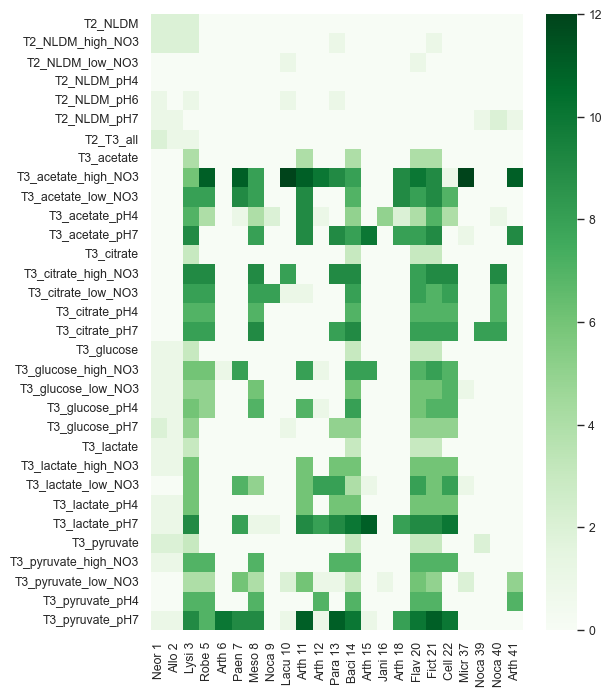

In [34]:
#Create a count of how many significant correlations each MAG has under each sub condition

MAG_cond_corr_dict = {}

for b in better_bin_list:
    b_conds_corrs_df = ij_vector_df[ij_vector_df['bin_i'].isin([b])|ij_vector_df['bin_j'].isin([b])]
    b_conds = {}
    b_edge_conds = b_conds_corrs_df['conditions']
    for c in sub_conds:
        b_conds[c] = 0
    for c_list in b_edge_conds:
        for c in c_list:
            b_conds[c] += 1
    MAG_cond_corr_dict[b] = b_conds

MAG_cond_corr_df = pd.DataFrame(MAG_cond_corr_dict).rename(bin_label_rename_dict,axis=1)

plt.figure(figsize=(6,8))
sns.heatmap(MAG_cond_corr_df,cmap='Greens')
plt.show()

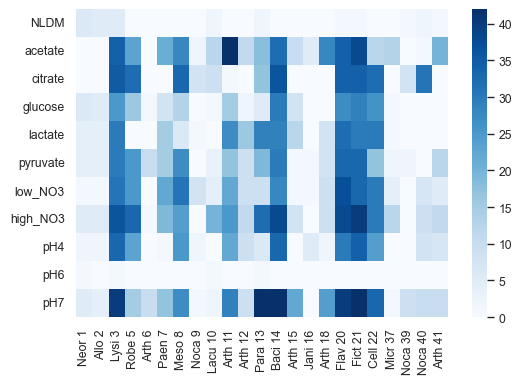

In [35]:
#Actually, make this for less fine groupings
cond_groups = ['NLDM','acetate','citrate','glucose','lactate','pyruvate','low_NO3','high_NO3','pH4','pH6','pH7']

bin_cond_group_count_dict = {}

for b in MAG_cond_corr_df.columns:
    df = MAG_cond_corr_df[b]
    b_cond_counts = []
    for cond in cond_groups:
        cond_sum = 0
        for i in df.index:
            if cond in i:
                cond_sum += df.T.loc[i]
        b_cond_counts.append(cond_sum)
    bin_cond_group_count_dict[b] = b_cond_counts

MAG_cond_groups_counts_df = pd.DataFrame(bin_cond_group_count_dict,index=cond_groups)

plt.figure(figsize=(6,4))
sns.heatmap(MAG_cond_groups_counts_df,cmap='Blues')
plt.show()

In [36]:
#Counting difference in richness (number) of MAGs between C contexts (belongs with abundance analysis)

#This is just a really rough alpha-diversity metric
#each of these counts how many of the MAGs are detected for each C source
print(f'Average N MAGs detected in T2 NLDM samples: {bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T2_NLDM_list].astype(bool).sum(axis=0).mean():.2f}')
print(f'Average N MAGs detected in T3 acetate samples: {bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T3_acetate_samples].astype(bool).sum(axis=0).mean():.2f}')
print(f'Average N MAGs detected in T3 citrate samples: {bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T3_citrate_samples].astype(bool).sum(axis=0).mean():.2f}')
print(f'Average N MAGs detected in T3 glucose samples: {bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T3_glucose_samples].astype(bool).sum(axis=0).mean():.2f}')
print(f'Average N MAGs detected in T3 lactate samples: {bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T3_lactate_samples].astype(bool).sum(axis=0).mean():.2f}')
print(f'Average N MAGs detected in T3 pyruvate samples: {bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T3_pyruvate_samples].astype(bool).sum(axis=0).mean():.2f}')

Average N MAGs detected in T2 NLDM samples: 12.67
Average N MAGs detected in T3 acetate samples: 7.09
Average N MAGs detected in T3 citrate samples: 9.78
Average N MAGs detected in T3 glucose samples: 9.78
Average N MAGs detected in T3 lactate samples: 9.84
Average N MAGs detected in T3 pyruvate samples: 10.00


In [37]:
#Run t-tests (Wald's) to see if the differences are significant
print('NLDM vs Acetate:',ttest_ind(bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T2_NLDM_list].astype(bool).sum(axis=0),bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T3_acetate_samples].astype(bool).sum(axis=0),equal_var=False))
print('NLDM vs Citrate:',ttest_ind(bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T2_NLDM_list].astype(bool).sum(axis=0),bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T3_citrate_samples].astype(bool).sum(axis=0),equal_var=False))
print('NLDM vs Glucose:',ttest_ind(bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T2_NLDM_list].astype(bool).sum(axis=0),bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T3_glucose_samples].astype(bool).sum(axis=0),equal_var=False))
print('NLDM vs Lactate:',ttest_ind(bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T2_NLDM_list].astype(bool).sum(axis=0),bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T3_lactate_samples].astype(bool).sum(axis=0),equal_var=False))
print('NLDM vs Pyruvate:',ttest_ind(bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T2_NLDM_list].astype(bool).sum(axis=0),bin_abunds_df[bin_abunds_df.index.isin(good_bin_list)][T3_pyruvate_samples].astype(bool).sum(axis=0),equal_var=False))

NLDM vs Acetate: TtestResult(statistic=np.float64(7.0476850754778395), pvalue=np.float64(9.837795848650422e-10), df=np.float64(70.60996651623134))
NLDM vs Citrate: TtestResult(statistic=np.float64(3.472253157839034), pvalue=np.float64(0.0009098752098168002), df=np.float64(66.80701092999409))
NLDM vs Glucose: TtestResult(statistic=np.float64(3.1411981823817894), pvalue=np.float64(0.0026219831380427227), df=np.float64(59.45021461323515))
NLDM vs Lactate: TtestResult(statistic=np.float64(3.2957596672850378), pvalue=np.float64(0.00159795504810042), df=np.float64(64.49473589642862))
NLDM vs Pyruvate: TtestResult(statistic=np.float64(2.8883744501917272), pvalue=np.float64(0.005403909987586604), df=np.float64(59.10653475270019))


In [38]:
#This is how I ran the link_clustering algorithm over various thresholds to check. 
#I'm doing the cooking show thing here, where I'm sharing the files I already made so that the link comm numbers don't get shuffled

#Export the mean correlation data (long form df) to run the link community analysis
#ij_vector_df[['bin_i','bin_j','mean_correlation']].to_csv('./data/EnCom_mean_fastspar_link_comms/EnCom_mean_fastspar_net.txt',sep='\t',header=False,index=False)

#Run the linkcomm script for a series of threshholds, so we can see which to pick. We'll use that after.
#threshholds = [i/100 for i in range(0,101)] #need floats for the thresholds but range returns ints, so do some division

#Running this function requires having the link_clustering.py file in the sh path where it can be called
#for t in threshholds:
#    os.system(f'python3 ~/linkcomm/link_clustering.py -w -r -t {t} ./data/EnCom_mean_fastspar_link_comms/EnCom_mean_fastspar_net.txt')

In [39]:
EnCom_mean_link_comm_files =  glob.glob('./data/EnCom_mean_fastspar_link_comms/*.edge2comm.txt')
EnCom_mean_link_comm_files

['./data/EnCom_mean_fastspar_link_comms/EnCom_mean_fastspar_net_thrS0.440000_thrD0.008032.edge2comm.txt',
 './data/EnCom_mean_fastspar_link_comms/EnCom_mean_fastspar_net_thrS0.420000_thrD0.008032.edge2comm.txt',
 './data/EnCom_mean_fastspar_link_comms/EnCom_mean_fastspar_net_thrS0.200000_thrD0.026104.edge2comm.txt',
 './data/EnCom_mean_fastspar_link_comms/EnCom_mean_fastspar_net_thrS0.740000_thrD0.000000.edge2comm.txt',
 './data/EnCom_mean_fastspar_link_comms/EnCom_mean_fastspar_net_thrS0.670000_thrD0.000000.edge2comm.txt',
 './data/EnCom_mean_fastspar_link_comms/EnCom_mean_fastspar_net_thrS0.560000_thrD0.018072.edge2comm.txt',
 './data/EnCom_mean_fastspar_link_comms/EnCom_mean_fastspar_net_thrS0.120000_thrD0.608698.edge2comm.txt',
 './data/EnCom_mean_fastspar_link_comms/EnCom_mean_fastspar_net_thrS0.500000_thrD0.018072.edge2comm.txt',
 './data/EnCom_mean_fastspar_link_comms/EnCom_mean_fastspar_net_thrS0.610000_thrD0.000000.edge2comm.txt',
 './data/EnCom_mean_fastspar_link_comms/EnCom_

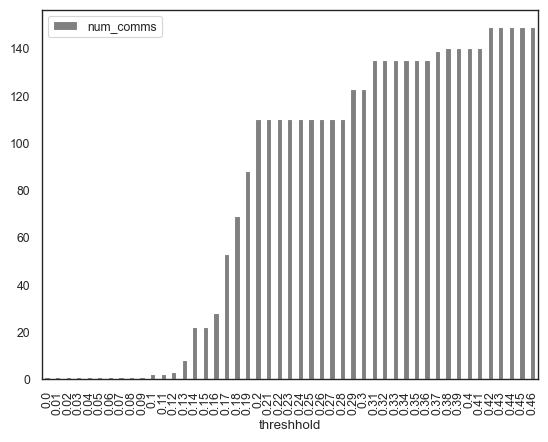

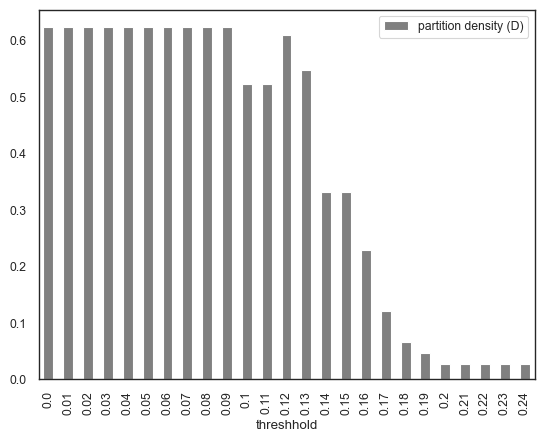

In [40]:
#Check for an appropriate threshold at the inflection points of the number of communities and partition density; this information is in the file names
t_list = []
D_list = []
max_num_comms_list = []
for f in EnCom_mean_link_comm_files:
    threshhold = float(f[66:70]) #slice the threshold from the file name
    t_list.append(float(threshhold))
    D = float(f[79:87]) #slice the partition density from the file name
    D_list.append(D)
    df = pd.read_csv(f,sep='\t',names=['node_i','node_j','link_comm'])
    n_comms = df['link_comm'].max()
    max_num_comms_list.append(int(n_comms))

#Make a df and plot the number of link comms for each threshold
t_n_comms_df = pd.DataFrame([t_list,max_num_comms_list]).T.rename({0:'threshhold',1:'num_comms'},axis=1).sort_values(by='threshhold')
t_n_comms_df[t_n_comms_df['num_comms']<150].plot(kind='bar',x='threshhold',y='num_comms',color='grey')
plt.show()

#Make a df and plot the partition density for each threshold
t_D_df = pd.DataFrame([t_list,D_list]).T.rename({0:'threshhold',1:'partition density (D)'},axis=1).sort_values(by='threshhold')
t_D_df[t_D_df['threshhold'] < 0.25].plot(kind='bar',x='threshhold',y='partition density (D)',color='grey')
plt.show()

In [41]:
#Based on the distribution and partition density, pick the threshold at the inflection points to balance community membership
threshhold = 0.17
threshold_link_comm_file = [i for i in EnCom_mean_link_comm_files if f'S{threshhold}' in i][0]
threshold_link_comm_file #check to make sure the selected file is correct

'./data/EnCom_mean_fastspar_link_comms/EnCom_mean_fastspar_net_thrS0.170000_thrD0.120166.edge2comm.txt'

In [42]:
#based on the inflection point in the number of linked communities, it seems like 0.17 is probably a good threshhold
EnCom_mean_link_comm_df = pd.read_csv(threshold_link_comm_file,sep='\t',names=['node_i','node_j','link_comm'])
EnCom_mean_link_comm_df

,node_i,node_j,link_comm
0,Bin_40,Bin_41,1
1,Bin_11,Bin_15,2
2,Bin_14,Bin_40,3
3,Bin_20,Bin_5,4
4,Bin_5,Bin_7,4
...,...,...,...
161,Bin_2,Bin_39,53
162,Bin_1,Bin_39,53
163,Bin_2,Bin_3,53
164,Bin_1,Bin_10,53


max edges per community =  10
min edges per community =  1


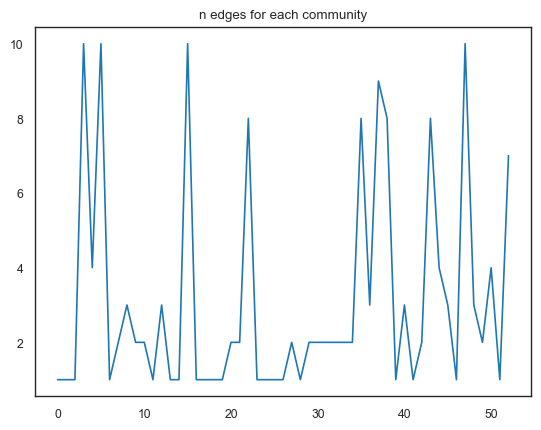

In [43]:
#How many edges are represented in each link community

#Iterate over each community, count edges in that community, and store those counts in an array
n_edges_list = []
for i in range(1,54):
    n_edges = len(EnCom_mean_link_comm_df[EnCom_mean_link_comm_df['link_comm']==i])
    n_edges_list.append(n_edges)
n_edges_list = np.array(n_edges_list)

#Print max and min
print('max edges per community = ',n_edges_list.max())
print('min edges per community = ',n_edges_list.min())

#Display per comm
plt.plot(n_edges_list)
plt.title('n edges for each community')
plt.show()

max MAGs per community =  11
min MAGs per community =  2


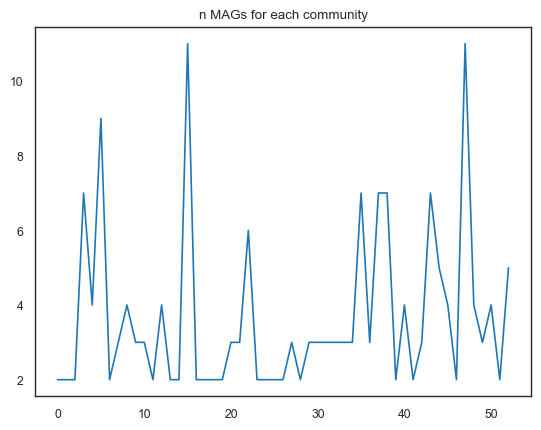

In [44]:
#How many MAGs are represented in each link community

#Iterate over each community, count unique MAGs in that community, and store those counts in an array
n_tax_list = []
for i in range(1,54):
    n_tax = len(set(EnCom_mean_link_comm_df[EnCom_mean_link_comm_df['link_comm']==i][['node_i','node_j']].melt()['value']))
    n_tax_list.append(n_tax)
n_tax_list = np.array(n_tax_list)

#Print max and min
print('max MAGs per community = ',n_tax_list.max())
print('min MAGs per community = ',n_tax_list.min())

#Display per comm
plt.plot(n_tax_list)
plt.title('n MAGs for each community')
plt.show()

In [45]:
#now, we want to reattach the sig conditions to each edge so we can load them as attributes in the network
EnCom_mean_link_comm_conds_df = EnCom_mean_link_comm_df.merge(ij_vector_df.rename({'bin_i':'node_i','bin_j':'node_j'},axis=1),how='left',on=['node_i','node_j']).copy()
EnCom_mean_link_comm_conds_df[EnCom_mean_link_comm_conds_df['node_i'].isin(['Bin_1','Bin_2'])]

,node_i,node_j,link_comm,conditions,mean_correlation
159,Bin_1,Bin_2,53,"[T2_NLDM, T2_NLDM_high_NO3, T2_NLDM_pH7, T2_T3...",0.669919
161,Bin_2,Bin_39,53,[T3_pyruvate],0.221800
162,Bin_1,Bin_39,53,[T3_pyruvate],0.276400
163,Bin_2,Bin_3,53,"[T2_NLDM, T2_NLDM_high_NO3]",0.323150
164,Bin_1,Bin_10,53,[T3_glucose_pH7],0.488200
165,Bin_1,Bin_3,53,"[T2_NLDM, T2_NLDM_high_NO3, T2_NLDM_pH6, T2_T3...",0.438375


In [46]:
#Another example
EnCom_mean_link_comm_conds_df[EnCom_mean_link_comm_conds_df['link_comm']==4]

,node_i,node_j,link_comm,conditions,mean_correlation
3,Bin_20,Bin_5,4,"[T3_acetate_high_NO3, T3_acetate_low_NO3, T3_c...",-0.053658
4,Bin_5,Bin_7,4,"[T3_acetate_high_NO3, T3_acetate_low_NO3, T3_g...",-0.064660
5,Bin_21,Bin_37,4,[T3_acetate_high_NO3],0.051100
6,Bin_13,Bin_21,4,"[T2_NLDM_high_NO3, T3_acetate_pH7, T3_citrate_...",0.014580
7,Bin_37,Bin_5,4,[T3_acetate_high_NO3],-0.024100
8,Bin_21,Bin_9,4,[T3_citrate_low_NO3],-0.012200
9,Bin_20,Bin_21,4,"[T3_acetate, T3_acetate_high_NO3, T3_acetate_l...",-0.020329
10,Bin_5,Bin_9,4,[T3_citrate_low_NO3],-0.065900
11,Bin_13,Bin_5,4,"[T3_acetate_high_NO3, T3_citrate_high_NO3, T3_...",0.038350
12,Bin_21,Bin_7,4,"[T3_acetate_high_NO3, T3_acetate_low_NO3, T3_g...",0.006743


In [47]:
#how many edges are in each link community
EnCom_mean_link_comm_conds_df['link_comm'].value_counts()

link_comm
4     10
6     10
16    10
48    10
38     9
23     8
36     8
39     8
44     8
53     7
5      4
45     4
51     4
9      3
13     3
37     3
41     3
46     3
49     3
8      2
10     2
11     2
21     2
22     2
28     2
30     2
31     2
32     2
33     2
34     2
35     2
43     2
50     2
1      1
2      1
3      1
7      1
12     1
14     1
15     1
17     1
18     1
19     1
20     1
24     1
25     1
26     1
27     1
29     1
40     1
42     1
47     1
52     1
Name: count, dtype: int64

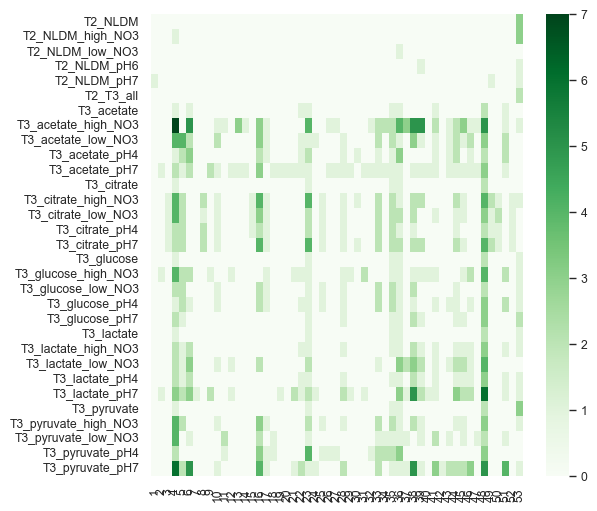

In [48]:
#Create a visual of all of the conditions where link community members have significant correlations
conditions = [] #list all conditions here
for i in range(1,54): #iterate through each link comm and get all conditions listed to put in master list
    cond_lists = EnCom_mean_link_comm_conds_df[EnCom_mean_link_comm_conds_df['link_comm']==i]['conditions'].to_list() #list of lists for each link comm edge
    for cond_list in cond_lists: #iterate through each edge conditions in the link comm
        for c in cond_list: #iterate through each condition
            conditions.append(c) #add each individual edge to the master list
conditions = sorted(list(set(conditions))) #use set to keep unique values, make it a list, then sort it to keep things orderly

lc_cond_counts = {} #Count how many instances of each of all conditions are significant for an edge in a link comm
for i in range(1,54): #iterate through each link comm
    cond_counts = {} #store the counts for each link comm individually
    for cond in conditions: #initialize for each condition
        cond_counts[cond] = 0 #set initial count to 0
    for cond_list in EnCom_mean_link_comm_conds_df[EnCom_mean_link_comm_conds_df['link_comm']==i]['conditions']: #iterate through each edge condition list for a link comm
        for c in cond_list: #iterate over each condition for that edge
            cond_counts[c] += 1 #add its count to the dictionary
    lc_cond_counts[i] = cond_counts #store the count dict for each link comm

#Convert the dictionary to a dataframe
LC_cond_count_df = pd.DataFrame(lc_cond_counts)

#Plot it in a quick heatmap
plt.figure(figsize=(6,6))
sns.heatmap(LC_cond_count_df,cmap='Greens',xticklabels=True)
plt.show()

#This is showing how many edges in a link community are significantly correlated under a given condition

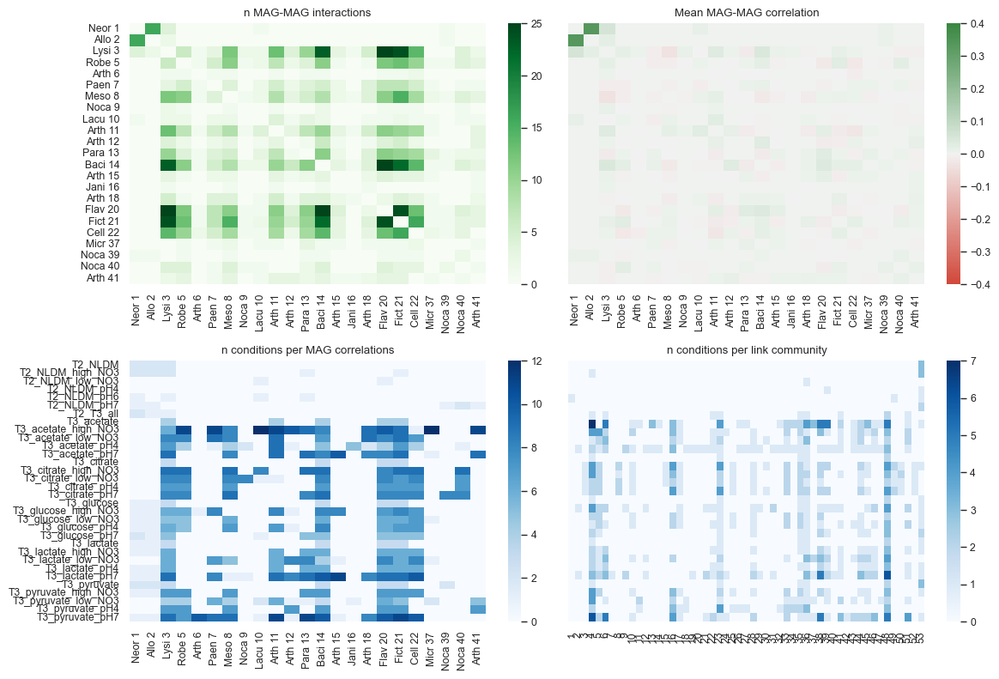

In [49]:
#Put all the heatmaps together in a 2x2 subplot grid

sns.set_context('paper')

fig,ax = plt.subplots(nrows=2,ncols=2,figsize=(12,8))

sns.heatmap(MAG_MAG_n_corr_df,cmap='Greens',xticklabels=True,yticklabels=True,ax=ax[0,0])
ax[0,0].set_title('n MAG-MAG interactions')

sns.heatmap(MAG_MAG_mean_corr_df,cmap=sns.diverging_palette(15, 130, as_cmap=True),xticklabels=True,yticklabels=False,vmin=-0.4,vmax=0.4,ax=ax[0,1])
#ax[0,1].set_yticklabels([])
ax[0,1].set_title('Mean MAG-MAG correlation')

sns.heatmap(MAG_cond_corr_df,cmap='Blues',xticklabels=True,yticklabels=True,ax=ax[1,0])
ax[1,0].set_title('n conditions per MAG correlations')

sns.heatmap(LC_cond_count_df,cmap='Blues',xticklabels=True,yticklabels=False,ax=ax[1,1])
#ax[1,1].set_yticklabels([])
ax[1,1].set_title('n conditions per link community')

plt.tight_layout()
plt.show()

In [50]:
#This part isn't super critical, but I used this ipywidget tool to manually pick the diverging color palette to go from gold to blue to match the network edges.

#import ipywidgets as widgets
#from IPython.display import display
#sns.choose_diverging_palette()
#sns.diverging_palette(60,250,s=99,l=65,sep=1,n=9,center='light',as_cmap=True)

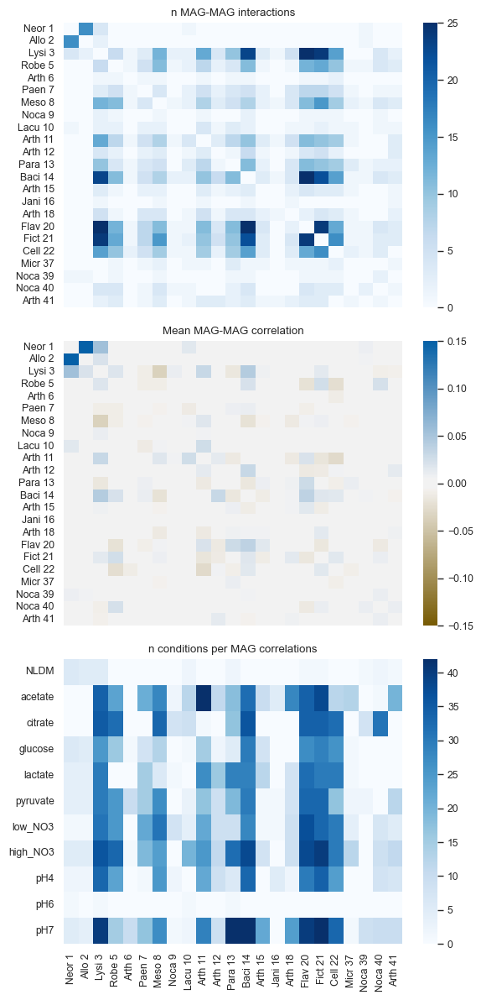

In [51]:
#I went through several iterations of these heatmaps before ultimately deciding not to include them in the figures, but I still find them somewhat informative.

sns.set_context('paper')
mpl.rcParams['pdf.fonttype'] = 42

fig,ax = plt.subplots(nrows=3,figsize=(6,12),sharex=True)

sns.heatmap(MAG_MAG_n_corr_df,cmap='Blues',xticklabels=False,yticklabels=True,ax=ax[0])
ax[0].set_title('n MAG-MAG interactions')

sns.heatmap(MAG_MAG_mean_corr_df,cmap=sns.diverging_palette(60,250,s=99,l=40,sep=10,n=9,center='light',as_cmap=True),xticklabels=False,yticklabels=True,vmin=-0.15,vmax=0.15,ax=ax[1])
#ax[0,1].set_yticklabels([])
ax[1].set_title('Mean MAG-MAG correlation')

sns.heatmap(MAG_cond_groups_counts_df,cmap='Blues',xticklabels=True,yticklabels=True,ax=ax[2])
ax[2].set_title('n conditions per MAG correlations')
plt.tight_layout()
#plt.savefig('../figs/corr_net_matrix/corr_heatmaps.pdf',dpi=300,bbox_inches='tight')
plt.show()

In [52]:
#Count the conditions that define the link communities
LC_cond_count_df[53][LC_cond_count_df[53]>0].sort_values(ascending=False)

T2_NLDM                 3
T3_pyruvate             3
T2_NLDM_high_NO3        3
T3_glucose_pH7          2
T2_T3_all               2
T3_pyruvate_high_NO3    1
T3_lactate_pH7          1
T3_lactate_pH4          1
T3_lactate_high_NO3     1
T3_lactate              1
T3_glucose_low_NO3      1
T3_glucose_pH4          1
T3_glucose_high_NO3     1
T3_glucose              1
T3_citrate_high_NO3     1
T3_acetate_high_NO3     1
T2_NLDM_pH7             1
T2_NLDM_pH6             1
T3_pyruvate_pH7         1
Name: 53, dtype: int64

In [53]:
#I want to make some plots better illustrating the conditions that represent each link comm

#Palette to map each condition to the colors used in other figures
cond_group_palette = {'acetate':'xkcd:turquoise',
    'glucose':'xkcd:olive',
    'citrate':'xkcd:peach',
    'pyruvate':'xkcd:crimson',
    'lactate':'xkcd:beige',
    'NLDM':'xkcd:light brown',
    'pH4':'xkcd:tangerine','pH6':'xkcd:moss','pH7':'xkcd:cerulean',
    'low_NO3':"xkcd:robin's egg blue",'high_NO3':'xkcd:sea blue'}

cond_groups = ['NLDM','acetate','citrate','glucose','lactate','pyruvate','low_NO3','high_NO3','pH4','pH6','pH7']
link_comm_cond_group_counts = {}
for i in range(1,54):
    cond_sum_series = LC_cond_count_df[i]
    cond_group_counts = {}
    for c in cond_groups:
        cond_group_counts[c] = sum(LC_cond_count_df[i][LC_cond_count_df[i].index.str.contains(c)])
    link_comm_cond_group_counts[i] = cond_group_counts

link_comm_cond_group_sum_df = pd.DataFrame(link_comm_cond_group_counts)
link_comm_cond_group_sum_df_melt = link_comm_cond_group_sum_df.reset_index(names='conditions').melt(id_vars='conditions') #melted version
link_comm_cond_group_sum_df

,1,2,3,4,5,6,7,8,9,10,...,44,45,46,47,48,49,50,51,52,53
NLDM,1,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,8
acetate,0,1,0,15,7,13,0,0,2,4,...,7,5,5,2,15,0,0,7,0,1
citrate,0,0,4,13,8,0,0,7,0,4,...,6,3,0,0,15,6,5,0,4,1
glucose,0,1,0,10,7,3,0,0,1,2,...,3,2,3,0,14,0,0,4,0,6
lactate,0,1,0,10,5,10,1,0,2,1,...,7,6,5,0,18,0,0,3,0,4
pyruvate,0,0,0,17,4,6,0,0,0,2,...,3,4,3,1,15,0,0,5,0,5
low_NO3,0,0,1,16,9,6,0,1,0,5,...,6,5,3,1,14,1,2,3,1,1
high_NO3,0,1,1,22,7,9,0,2,1,3,...,6,7,4,1,19,2,1,4,1,8
pH4,0,0,1,8,7,6,0,2,0,2,...,5,1,3,0,13,1,1,5,1,2
pH6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


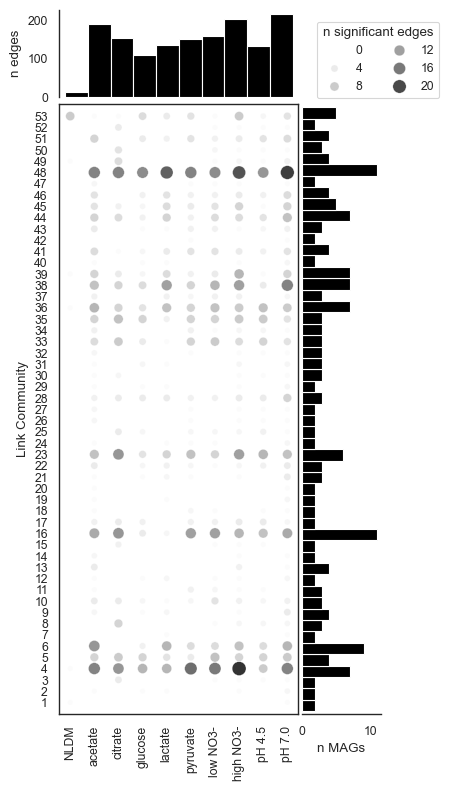

In [54]:
#Make my own version of an UpSet plot to illustrate this data for figure 3

fig,ax = plt.subplots(nrows=2,ncols=2,figsize=(4,8),sharex=False,sharey=False,height_ratios=(.125,.875),width_ratios=(.75,.25))

#Show how many edges are significant under each condition (From correlation networks)
link_comm_cond_group_sum_df[link_comm_cond_group_sum_df.index!='pH6'].sum(axis=1).plot(kind='bar',color='black',width=1,ax=ax[0,0])
ax[0,0].margins(x=0.01)
ax[0,0].set_xticks([])
ax[0,0].set_ylabel('n edges')
ax[0,0].spines['top'].set_visible(False)
ax[0,0].spines['right'].set_visible(False)
ax[0,0].spines['bottom'].set_visible(False)

ax[0,1].axis('off')

#Show how many times all edges in a link community are significantly correlated under a given condition by size and color
sns.scatterplot(link_comm_cond_group_sum_df_melt[link_comm_cond_group_sum_df_melt['conditions']!='pH6'],y='variable',x='conditions',size='value',sizes=(10,100),hue='value',alpha=.8,palette='Greys',ax=ax[1,0],legend=True)
ax[1,0].set_ylabel('Link Community')
ax[1,0].set_xlabel('')
xticks = link_comm_cond_group_sum_df_melt[link_comm_cond_group_sum_df_melt['conditions']!='pH6'].conditions.unique()
xlabels = ['NLDM','acetate','citrate','glucose','lactate','pyruvate','low NO3-','high NO3-','pH 4.5','pH 7.0']
ax[1,0].set_xticks(xticks)
ax[1,0].set_xticklabels(labels=xlabels,rotation=90)
ax[1,0].set_yticks(range(1,54))
ax[1,0].set_yticklabels(labels=range(1,54))
ax[1,0].margins(y=0.02)
ax[1,0].get_legend().remove()
fig.legend(bbox_to_anchor=(1.125,.975),title='n significant edges',ncols=2)


#Display how many MAGs are in each link community
pd.Series(n_tax_list,index=range(1,54)).plot(kind='barh',color='black',width=1,ax=ax[1,1])
ax[1,1].set_yticks([])
ax[1,1].set_xlabel('n MAGs')
ax[1,1].spines['top'].set_visible(False)
ax[1,1].spines['right'].set_visible(False)
ax[1,1].spines['left'].set_visible(False)

plt.tight_layout(h_pad=0,w_pad=0)
#plt.savefig('../figs/corr_net_matrix/link_comm_upset.pdf',dpi=300,bbox_inches='tight')
plt.show()

In [55]:
#Create separate dfs to show the relative contributions of different c sources, pHs, and [NO3-] to each link comm

link_comm_cond_group_sum_df_c = link_comm_cond_group_sum_df[link_comm_cond_group_sum_df.index.isin(['NLDM','acetate','citrate','glucose','lactate','pyruvate'])]
link_comm_cond_group_sum_df_c = link_comm_cond_group_sum_df_c.div(link_comm_cond_group_sum_df_c.sum())
link_comm_cond_group_sum_df_p = link_comm_cond_group_sum_df[link_comm_cond_group_sum_df.index.isin(['pH4','pH6','pH7'])]
link_comm_cond_group_sum_df_p = link_comm_cond_group_sum_df_p.div(link_comm_cond_group_sum_df_p.sum())
link_comm_cond_group_sum_df_n = link_comm_cond_group_sum_df[link_comm_cond_group_sum_df.index.isin(['low_NO3','high_NO3'])]
link_comm_cond_group_sum_df_n = link_comm_cond_group_sum_df_n.div(link_comm_cond_group_sum_df_n.sum())

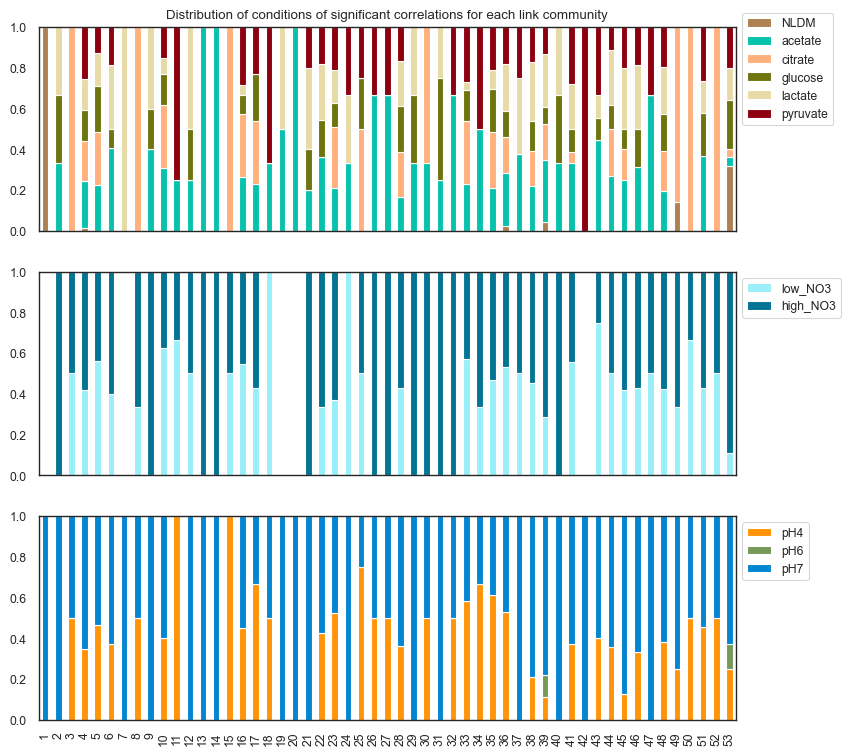

In [56]:
#Just doing some different visualizations to help interpret the proportion of conditions contributing to each link comm

fig,ax = plt.subplots(nrows=3,figsize=(9,9),sharex=True)

link_comm_cond_group_sum_df_c.T.plot(kind='bar',stacked=True,color=cond_group_palette,ax=ax[0])
ax[0].legend(bbox_to_anchor=(1,1.1))
ax[0].set_title('Distribution of conditions of significant correlations for each link community')

link_comm_cond_group_sum_df_n.T.plot(kind='bar',stacked=True,color=cond_group_palette,ax=ax[1])
ax[1].legend(bbox_to_anchor=(1,1))
#ax[1].set_title('Distribution of NO3 conditions of significant correlations for each link community')

link_comm_cond_group_sum_df_p.T.plot(kind='bar',stacked=True,color=cond_group_palette,ax=ax[2])
ax[2].legend(bbox_to_anchor=(1,1))
#ax[2].set_title('Distribution of pH conditions of significant correlations for each link community')

plt.show()

In [57]:
#If you prefer to read numbers, you can here

for i in range(1,54):
    print(i,'\n',LC_cond_count_df[i][LC_cond_count_df[i]>0].sort_values(ascending=False),'\n')

1 
 T2_NLDM_pH7    1
Name: 1, dtype: int64 

2 
 T3_acetate_pH7         1
T3_glucose_high_NO3    1
T3_lactate_pH7         1
Name: 2, dtype: int64 

3 
 T3_citrate_high_NO3    1
T3_citrate_low_NO3     1
T3_citrate_pH4         1
T3_citrate_pH7         1
Name: 3, dtype: int64 

4 
 T3_acetate_high_NO3     7
T3_pyruvate_pH7         6
T3_acetate_low_NO3      4
T3_pyruvate_low_NO3     4
T3_pyruvate_high_NO3    4
T3_citrate_high_NO3     4
T3_citrate_low_NO3      4
T3_glucose_high_NO3     4
T3_lactate_pH7          3
T3_glucose_pH7          2
T3_pyruvate_pH4         2
T3_lactate_pH4          2
T3_lactate_low_NO3      2
T3_lactate_high_NO3     2
T3_glucose_low_NO3      2
T3_citrate_pH7          2
T3_citrate_pH4          2
T3_acetate_pH7          2
T3_glucose_pH4          1
T3_lactate              1
T3_acetate              1
T3_glucose              1
T3_pyruvate             1
T3_citrate              1
T3_acetate_pH4          1
T2_NLDM_high_NO3        1
Name: 4, dtype: int64 

5 
 T3_acetate_low_N

In [58]:
#Some more numbers to count total significant edges found in each condition
LC_cond_count_df.sum(axis=1).sort_values(ascending=False)

T3_acetate_high_NO3     69
T3_pyruvate_pH7         60
T3_lactate_pH7          52
T3_citrate_high_NO3     44
T3_acetate_pH7          44
T3_acetate_low_NO3      41
T3_citrate_pH7          41
T3_citrate_low_NO3      36
T3_glucose_high_NO3     35
T3_lactate_low_NO3      34
T3_pyruvate_high_NO3    29
T3_glucose_pH4          28
T3_acetate_pH4          28
T3_pyruvate_pH4         28
T3_citrate_pH4          28
T3_pyruvate_low_NO3     25
T3_lactate_pH4          22
T3_glucose_low_NO3      22
T3_lactate_high_NO3     22
T3_glucose_pH7          17
T3_acetate              10
T3_pyruvate              9
T3_lactate               7
T3_glucose               7
T3_citrate               6
T2_NLDM_high_NO3         4
T2_NLDM_pH7              3
T2_NLDM                  3
T2_T3_all                2
T2_NLDM_pH6              2
T2_NLDM_low_NO3          1
dtype: int64

In [59]:
#All link communities that contain bins 1 (Neo) and 2 (Allo); spoilers: it's just one.
EnCom_mean_link_comm_conds_df[EnCom_mean_link_comm_conds_df['node_i'].isin(['Bin_2','Bin_1'])|EnCom_mean_link_comm_conds_df['node_j'].isin(['Bin_2','Bin_1'])]

,node_i,node_j,link_comm,conditions,mean_correlation
159,Bin_1,Bin_2,53,"[T2_NLDM, T2_NLDM_high_NO3, T2_NLDM_pH7, T2_T3...",0.669919
161,Bin_2,Bin_39,53,[T3_pyruvate],0.221800
162,Bin_1,Bin_39,53,[T3_pyruvate],0.276400
163,Bin_2,Bin_3,53,"[T2_NLDM, T2_NLDM_high_NO3]",0.323150
164,Bin_1,Bin_10,53,[T3_glucose_pH7],0.488200
165,Bin_1,Bin_3,53,"[T2_NLDM, T2_NLDM_high_NO3, T2_NLDM_pH6, T2_T3...",0.438375


In [60]:
#Let's see which link comms the other members of 53 are found in since that's the potential connection between Neor 1 and Allo 2 with the rest of the communities
#Another spoiler: It's all of the rest of the communities, with a few differences for each bin 3, 10, and 39

secondary_comms = list(set(list(EnCom_mean_link_comm_conds_df[EnCom_mean_link_comm_conds_df['node_i'].isin(['Bin_39'])|EnCom_mean_link_comm_conds_df['node_j'].isin(['Bin_39'])]['link_comm'].unique()) +
list(EnCom_mean_link_comm_conds_df[EnCom_mean_link_comm_conds_df['node_i'].isin(['Bin_10'])|EnCom_mean_link_comm_conds_df['node_j'].isin(['Bin_10'])]['link_comm'].unique()) +
list(EnCom_mean_link_comm_conds_df[EnCom_mean_link_comm_conds_df['node_i'].isin(['Bin_3'])|EnCom_mean_link_comm_conds_df['node_j'].isin(['Bin_3'])]['link_comm'].unique())))

b3_comms = list(EnCom_mean_link_comm_conds_df[EnCom_mean_link_comm_conds_df['node_i'].isin(['Bin_3'])|EnCom_mean_link_comm_conds_df['node_j'].isin(['Bin_3'])]['link_comm'].unique())
b10_comms = list(EnCom_mean_link_comm_conds_df[EnCom_mean_link_comm_conds_df['node_i'].isin(['Bin_10'])|EnCom_mean_link_comm_conds_df['node_j'].isin(['Bin_10'])]['link_comm'].unique())
b39_comms = list(EnCom_mean_link_comm_conds_df[EnCom_mean_link_comm_conds_df['node_i'].isin(['Bin_39'])|EnCom_mean_link_comm_conds_df['node_j'].isin(['Bin_39'])]['link_comm'].unique())

In [61]:
#create a color palette to be consistent for plotting link comms
n_link_comms = EnCom_mean_link_comm_conds_df['link_comm'].max()

#Store a unique color (hex code) for each link comm here
link_comm_pal = {}

#Set a random seed for consistency. Using today's date for now.
random.seed(20260303)

#Iterate over each link comm
for i in range(1,n_link_comms+1):
    rand_color = random.choice(xkcd_color_df['hex']) #pick a random color from the xkcd set
    if rand_color not in link_comm_pal.values(): #make sure it's unique
        link_comm_pal[i] = rand_color #assign it to a link comm
    elif rand_color in link_comm_pal.values():
        new_rand_color = random.choice(xkcd_color_df['hex'])
        link_comm_pal[i] = new_rand_color

In [62]:
link_comm_members_dict = {}
for i in range(1,54):
    df = EnCom_mean_link_comm_conds_df[EnCom_mean_link_comm_conds_df['link_comm']==i]
    i_list = df['node_i'].to_list()
    j_list = df['node_j'].to_list()
    link_comm_members = list(set(i_list + j_list))
    link_comm_members_dict[i] = link_comm_members

link_comm_members_dict

{1: ['Bin_41', 'Bin_40'],
 2: ['Bin_15', 'Bin_11'],
 3: ['Bin_14', 'Bin_40'],
 4: ['Bin_5', 'Bin_21', 'Bin_13', 'Bin_9', 'Bin_20', 'Bin_7', 'Bin_37'],
 5: ['Bin_21', 'Bin_18', 'Bin_22', 'Bin_5'],
 6: ['Bin_16',
  'Bin_12',
  'Bin_13',
  'Bin_9',
  'Bin_20',
  'Bin_11',
  'Bin_7',
  'Bin_6',
  'Bin_37'],
 7: ['Bin_15', 'Bin_12'],
 8: ['Bin_21', 'Bin_5', 'Bin_40'],
 9: ['Bin_15', 'Bin_13', 'Bin_37', 'Bin_7'],
 10: ['Bin_8', 'Bin_18', 'Bin_22'],
 11: ['Bin_16', 'Bin_41', 'Bin_12'],
 12: ['Bin_15', 'Bin_20'],
 13: ['Bin_41', 'Bin_13', 'Bin_37', 'Bin_7'],
 14: ['Bin_18', 'Bin_41'],
 15: ['Bin_22', 'Bin_40'],
 16: ['Bin_16',
  'Bin_39',
  'Bin_3',
  'Bin_12',
  'Bin_13',
  'Bin_9',
  'Bin_20',
  'Bin_8',
  'Bin_7',
  'Bin_10',
  'Bin_37'],
 17: ['Bin_21', 'Bin_5'],
 18: ['Bin_41', 'Bin_20'],
 19: ['Bin_15', 'Bin_8'],
 20: ['Bin_15', 'Bin_41'],
 21: ['Bin_15', 'Bin_18', 'Bin_22'],
 22: ['Bin_6', 'Bin_14', 'Bin_11'],
 23: ['Bin_21', 'Bin_5', 'Bin_3', 'Bin_39', 'Bin_12', 'Bin_10'],
 24: ['Bin_1

In [63]:
#make the link comm member dict a pkl file to use in another analysis

with open('./data/link_comm_members.pkl','wb') as f:
    pickle.dump(link_comm_members_dict,f)
    f.close()

In [64]:
#How often are any two MAGs found in the same link community?
ij_co_occur_dict = {}
for i in range(1,54):
    comm = link_comm_members_dict[i]
    for i in comm:
        if i != j:
            for j in comm:
                if (i,j) in ij_co_occur_dict.keys():
                    if (j,i) not in ij_co_occur_dict.keys():
                        ij_co_occur_dict[(i,j)] += 1
                else:
                    if (j,i) not in ij_co_occur_dict.keys():
                        ij_co_occur_dict[(i,j)] = 1
i_list = []
j_list = []
v_list = []
for k,v in ij_co_occur_dict.items():
    i_list.append(bin_label_rename_dict[k[0]])
    j_list.append(bin_label_rename_dict[k[1]])
    v_list.append(v)

pd.DataFrame({'Bin_i':i_list,'Bin_j':j_list,'co-occurrences':v_list}).sort_values(by='co-occurrences',ascending=False)[0:50]

,Bin_i,Bin_j,co-occurrences
22,Para 13,Paen 7,11
23,Para 13,Micr 37,10
110,Lysi 3,Lacu 10,10
25,Noca 9,Flav 20,8
94,Noca 39,Lysi 3,8
36,Arth 18,Cell 22,8
101,Noca 39,Lacu 10,8
32,Paen 7,Micr 37,7
104,Lysi 3,Arth 12,6
30,Flav 20,Micr 37,6


In [65]:
MAG_num_dict = {'Neor 1':1, 
'Allo 2':2, 
'Lysi 3':3, 
'Robe 5':5, 
'Arth 6':6, 
'Paen 7':7, 
'Meso 8':8, 
'Noca 9':9, 
'Lacu 10':10, 
'Arth 11':11, 
'Arth 12':12, 
'Para 13':13, 
'Baci 14':14, 
'Arth 15':15, 
'Jani 16':16, 
'Arth 18':18, 
'Flav 20':20, 
'Fict 21':21,
'Cell 22':22, 
'Micr 37':37, 
'Noca 39':39, 
'Noca 40':40, 
'Arth 41':41}

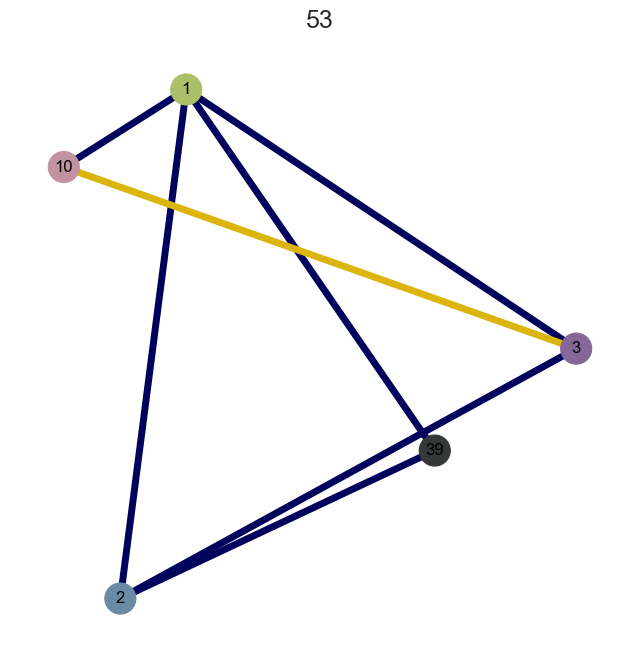

In [66]:
#Create network diagrams for each link comm, coloring each edge by the sign of the mean correlation between those MAGs
#This plotter is flexible: You can plot a single EnCom or you can plot all of the EnComs that a single MAG is found in together

def link_comm_net_plotter(bin_num=None,comm_num=None,comm_list=None,ax=None,sig_link_comms=False,correlation=False):
    """Plot either a single link community network or a network of all of the link communities that a bin is found in"""
    
    df_net = EnCom_mean_link_comm_conds_df.copy() #start by getting a copy of the link comm df
    if comm_num!=None: #The comm_num variable determines which single link_comm to plot
        df_net = df_net[df_net['link_comm']==comm_num] #Subset the df to just one link comm

    if comm_list!=None: #This variable is for plotting a list of specific link comms
        df_net = df_net[df_net['link_comm'].isin(comm_list)]

    #Create the networkx object
    G_link_comm = nx.from_pandas_edgelist(df_net,source='node_i',target='node_j',edge_attr=['link_comm','conditions','mean_correlation'])

    #Set the size of the nodes 
    size_dict = bin_abunds_by_condition_dict['All'] #Get the mean abundance for each bin for this condition to size the nodes

    #node_sizes = []
    #for node in G_link_comm.nodes():
    #    size = size_dict[node] #Determine size for each bin based on mean in the condition
    #    node_sizes.append(size*10) #Scale the size up for plotting aesthetics

    node_color_list = [] #Color the nodes based on the previously identified palette for each bin by its genus
    for node in G_link_comm.nodes():
        node_color_list.append(bin_pal[node])

    nx.relabel_nodes(G_link_comm,bin_label_rename_dict,copy=False) #rename the nodes to have nicer labels, E.g., 'Allo 2'

    edges = G_link_comm.edges() #Extract edges object for annotating the plot

    G_link_comm_edge_list = [G_link_comm[u][v]['link_comm'] for u,v in edges] #list of link comm each edge belongs to
    G_link_comm_correlation_edge_list = [G_link_comm[u][v]['mean_correlation'] for u,v in edges] #list of mean correlation value for each edge

    if bin_num == None:
        sig_comms_list = [comm_num]
    elif bin_num != 'All':
        sig_comms_list = EnCom_mean_link_comm_df[EnCom_mean_link_comm_df['node_i'].isin([bin_num])|EnCom_mean_link_comm_df['node_j'].isin([bin_num])]['link_comm'].unique()
    elif bin_num == 'All':
        sig_comms_list = EnCom_mean_link_comm_df['link_comm'].unique()

    #Give each link comm a unique color
    link_comm_color_dict = {}
    for comm in set(G_link_comm_edge_list):
        if sig_link_comms == False:
            link_comm_color_dict[comm] = link_comm_pal[comm]
        elif sig_link_comms == True:
            if comm in sig_comms_list:
                link_comm_color_dict[comm] = link_comm_pal[comm]
            elif comm not in sig_comms_list:
                link_comm_color_dict[comm] = 'lightgrey'
    

    #This section generates a palette with unique colors for each link comm. Use if correlation != True. Otherwise, use sign of mean correlation value to color edges (gold and blue)
    edge_color_list_G_link_comm = [] #Create list of colors for edges based on link comm membership
    edge_width_list_link_comm = []
    for i in range(len(G_link_comm_edge_list)):
        comm = G_link_comm_edge_list[i]
        
        color = link_comm_color_dict[G_link_comm_edge_list[i]]
        if comm_list!=None: #If specific link comms are specified, give each of them a unique color for all of their edges from the palette
            edge_color_list_G_link_comm.append(color)
            edge_width_list_link_comm.append(2.5)

        elif comm_num==None: #if the comm_num is not specified, give all link comms a unique color
            edge_color_list_G_link_comm.append(color)
            #sig_link_comms calls for sizing edges differently whether they're in the dataset or not; all edges are drawn but the specified ones will be larger
            if sig_link_comms == False: #if False, then all edges are the same size
                edge_width_list_link_comm.append(1)
            elif sig_link_comms == True: #If True, the edges in the specified set are larger by an order of magnitude
                if comm in sig_comms_list:
                    edge_width_list_link_comm.append(5)
                elif comm not in sig_comms_list:
                    edge_width_list_link_comm.append(.5)

        elif comm_num!=None: #If a specific link_comm is specified, color it based on its unique color and set its size
            if comm == comm_num:
                edge_color_list_G_link_comm.append(color)
                edge_width_list_link_comm.append(5)
            elif comm != comm_num: #and make all edges from other comms dissapear by setting their width to 0
                edge_color_list_G_link_comm.append(color)
                edge_width_list_link_comm.append(.0)

    #If specified, throw away the unique colors and color edges to be plotted based on their correlation sign value (blue and gold)
    if correlation == True:
        #reset these lists for the edges' color and width
        edge_color_list_G_link_comm = [] #Create list of colors for edges based on mean_correlation values
        edge_width_list_link_comm = []
        for i in range(len(G_link_comm_edge_list)):
            comm = G_link_comm_edge_list[i]
            mean_correlation = G_link_comm_correlation_edge_list[i]
            if comm in sig_comms_list:
                edge_width_list_link_comm.append(5) #if comm is specified above, set edge with to 5
                if mean_correlation > 0:
                    edge_color_list_G_link_comm.append('xkcd:dark blue') #positive
                elif mean_correlation < 0:
                    edge_color_list_G_link_comm.append('xkcd:gold') #negative
            elif comm not in sig_comms_list:
                edge_width_list_link_comm.append(0.1) #make other edges that may be present small and light grey
                edge_color_list_G_link_comm.append('lightgrey')
    
    #Rather than use the MAG names here, use just the MAG number since the plots get hard to read when they're small
    label_dict = {}
    for l in list(G_link_comm.nodes()):
        label_dict[l] = MAG_num_dict[l]

    #Now, let's create the network plots
    if ax==None: #This is for if the network is to stand alone
        fig,ax=plt.subplots(figsize=(8,8))
        #Draw the network
        nx.draw_networkx(G_cc,with_labels=False,pos=G_cc_pos_spring_locked,edge_color=None,node_color=None,width=0,node_size=0,ax=ax) #create an invisible network to make sure each node is in the same place
        #Now draw the network that we got the parts for above
        nx.draw_networkx(G_link_comm,with_labels=True,labels=label_dict,pos=G_cc_pos_spring_locked,edge_color=edge_color_list_G_link_comm,node_color=node_color_list,width=edge_width_list_link_comm,node_size=500,ax=ax)
        ax.axis('off') #Get rid of the box around the axis
        
        #Label based on the data specified
        if comm_num!=None:
            plt.title(f'{comm_num}',fontsize=18)
        elif comm_list!=None:
            plt.title(f'{bin_num} connected link communities',fontsize=18)
        elif bin_num=='All':
            plt.title(f'All Link community networks',fontsize=18)
        else:
            plt.title(f'Link community networks (n = {len(sig_comms_list)}) | {bin_label_rename_dict[bin_num]}',fontsize=18)
        
    elif ax!=None: #This is for adding each network to a subplot array
        nx.draw_networkx(G_cc,with_labels=False,pos=G_cc_pos_spring_locked,edge_color=None,node_color=None,width=0,node_size=0,ax=ax) #create an invisible network to make sure each node is in the same place
        #Now draw the network that we got the parts for above
        nx.draw_networkx(G_link_comm,with_labels=True,labels=label_dict,font_size=9,pos=G_cc_pos_spring_locked,edge_color=edge_color_list_G_link_comm,
        node_color=node_color_list,width=[i/2.2 for i in edge_width_list_link_comm],node_size=100,ax=ax) #For the subplots, the edge with and node sizes are standardized for scaling purposes
        for s in ['top','right','left','bottom']:
            ax.spines[s].set(ls=':',lw=2,color='xkcd:light grey') #For the subplot grid, I made the axis borders these dashed grey lines to help visually separate them
        ax.set_title(f'{comm_num}',fontsize=16) #label each subplot by the comm number
        if comm_num==None:
            ax.set_title('All',fontsize=16)

    #plt.show()

link_comm_net_plotter(bin_num=None,comm_num=53,sig_link_comms=True,correlation=True)

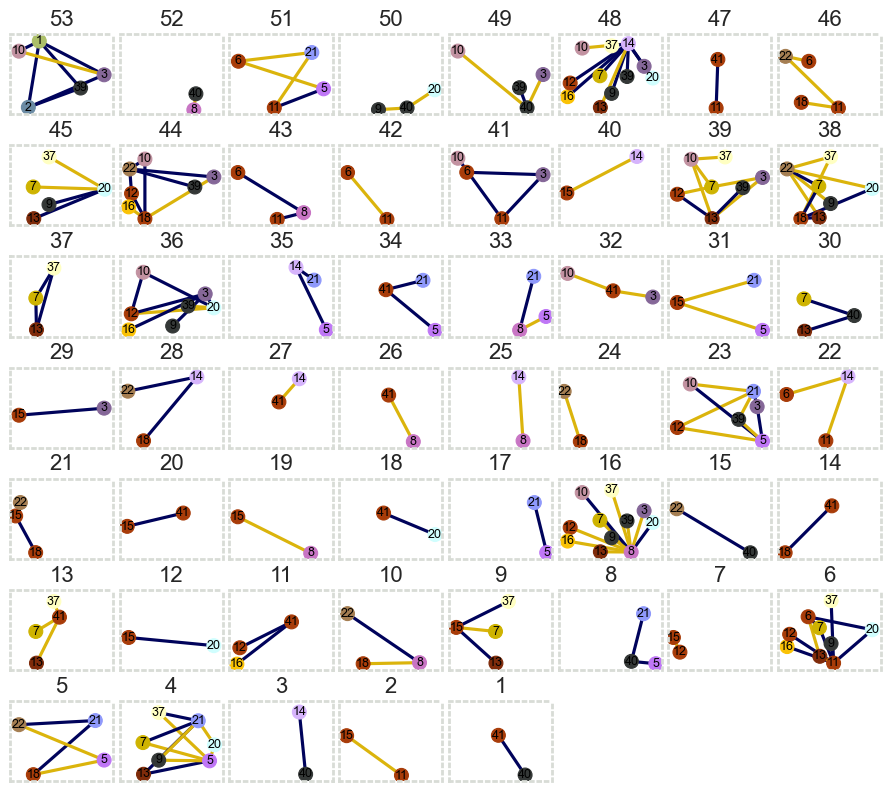

In [67]:
#Make a subplot grid off each link comm for figure 3

fig,ax = plt.subplots(figsize=(9,8),nrows=7,ncols=8)

#Counters to use to iterate over each axis
n_rows=0
n_cols=0
for i in list(range(53,0,-1)): #iterate over each link comm number, in reverse
    link_comm_net_plotter(bin_num=None,comm_num=i,sig_link_comms=True,correlation=True,ax=ax[n_rows,n_cols])
    n_cols += 1 #step through the row by each column
    if n_cols > 7:
        n_rows += 1 #Move to next row when last column is reached
        n_cols = 0 #reset column number

#Drop the last three subplots to clear empty space
ax[6,5].axis('off')
ax[6,6].axis('off')
ax[6,7].axis('off')

plt.tight_layout(h_pad=0.5,w_pad=0.5)
#plt.savefig('../figs/corr_net_matrix/link_comm_matrix.pdf',dpi=300,bbox_inches='tight')
plt.show()

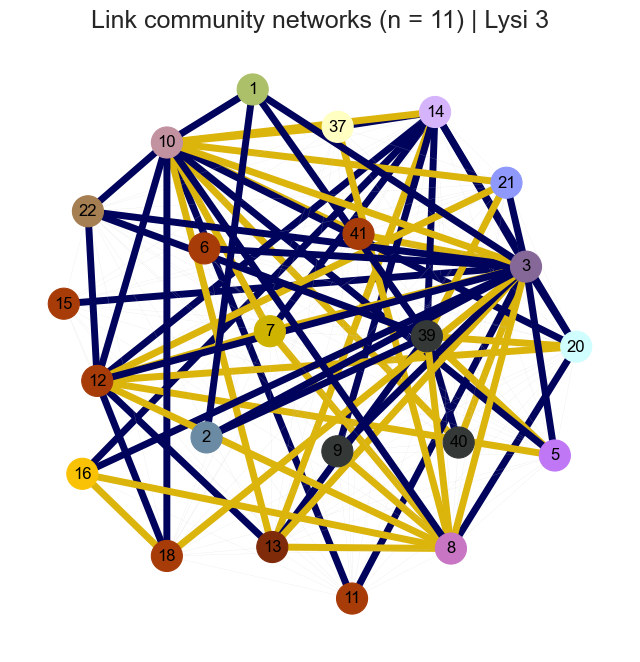

In [68]:
link_comm_net_plotter(bin_num='Bin_3',comm_num=None,sig_link_comms=True,correlation=True)

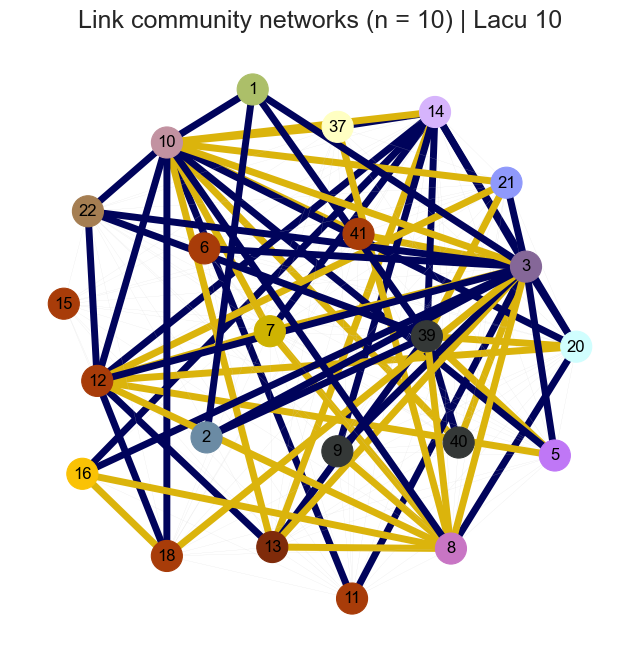

In [69]:
link_comm_net_plotter(bin_num='Bin_10',comm_num=None,sig_link_comms=True,correlation=True)

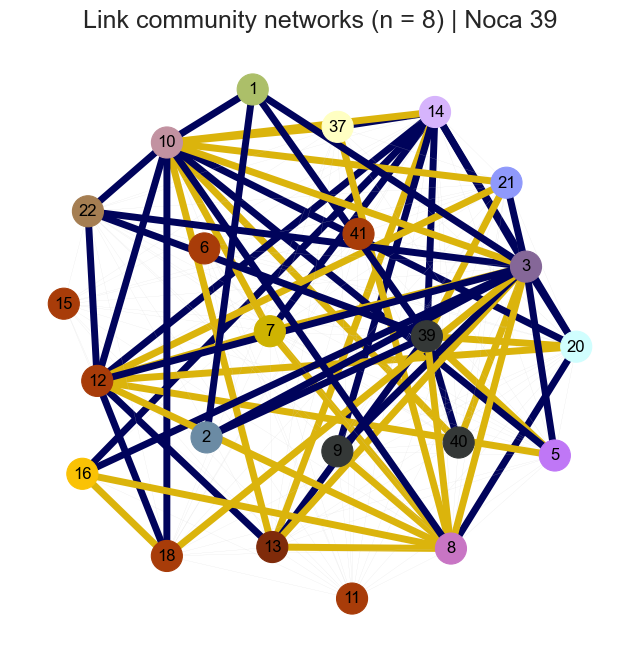

In [70]:
link_comm_net_plotter(bin_num='Bin_39',comm_num=None,sig_link_comms=True,correlation=True)

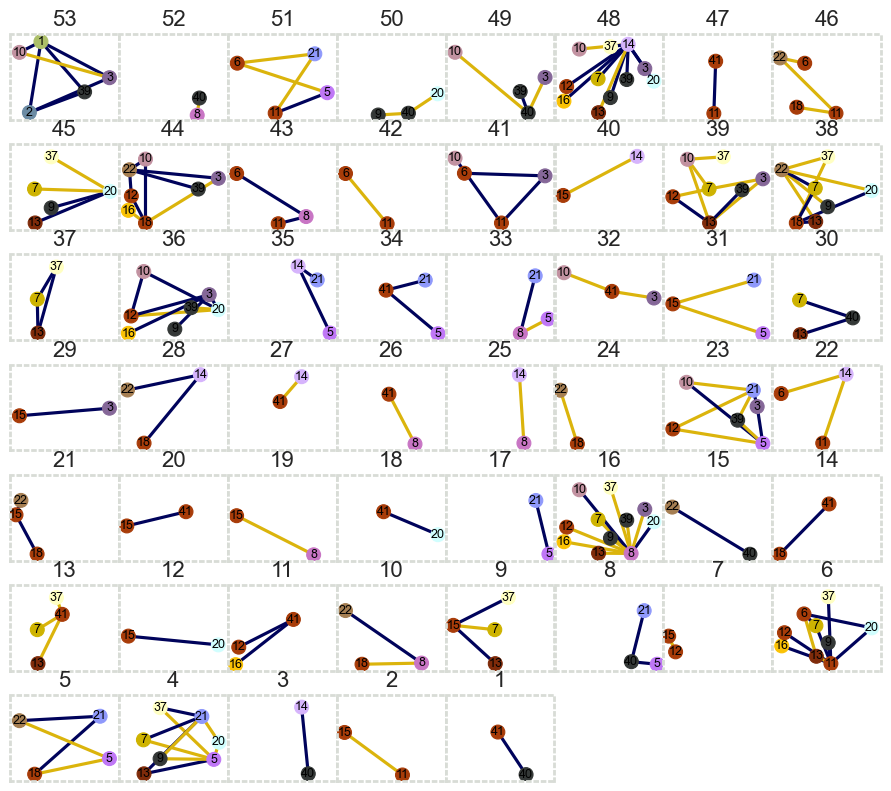

In [71]:
fig,ax = plt.subplots(figsize=(9,8),nrows=7,ncols=8)

n_rows=0
n_cols=0
for i in list(range(53,0,-1)):
    link_comm_net_plotter(bin_num=None,comm_num=i,sig_link_comms=True,correlation=True,ax=ax[n_rows,n_cols])
    n_cols += 1
    if n_cols > 7:
        n_rows += 1
        n_cols = 0

ax[6,5].axis('off')
ax[6,6].axis('off')
ax[6,7].axis('off')

plt.tight_layout(h_pad=0,w_pad=0)

#plt.savefig('../figs/corr_net_matrix/link_comm_matrix.pdf',dpi=300,bbox_inches='tight')

plt.show()

/var/folders/71/xm3vqjnn3xv2vtqkfhmrtzyh0000gp/T/ipykernel_66556/3013258986.py:110: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig,ax=plt.subplots(figsize=(8,8))


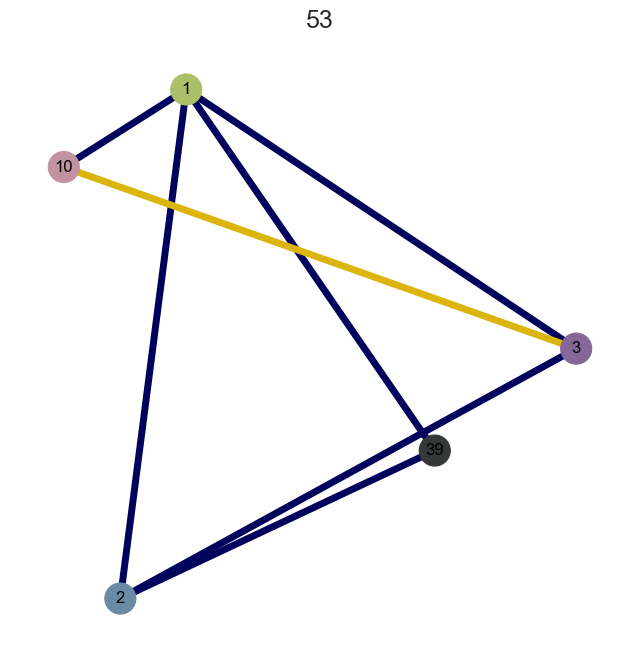

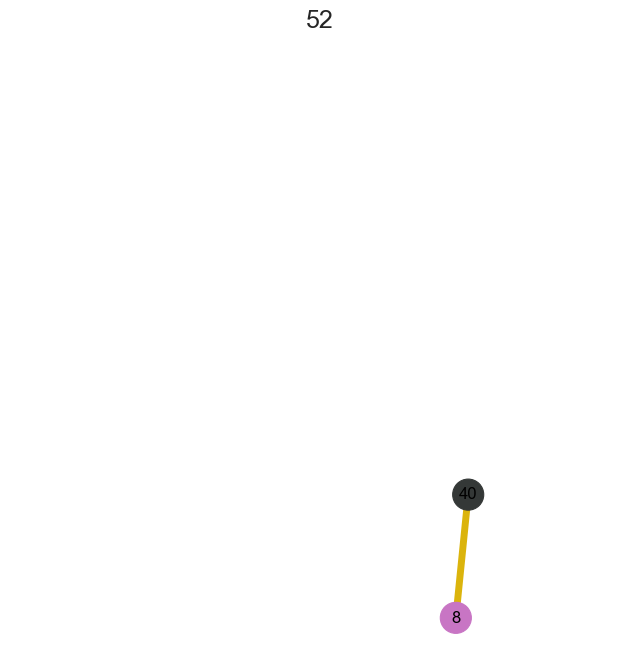

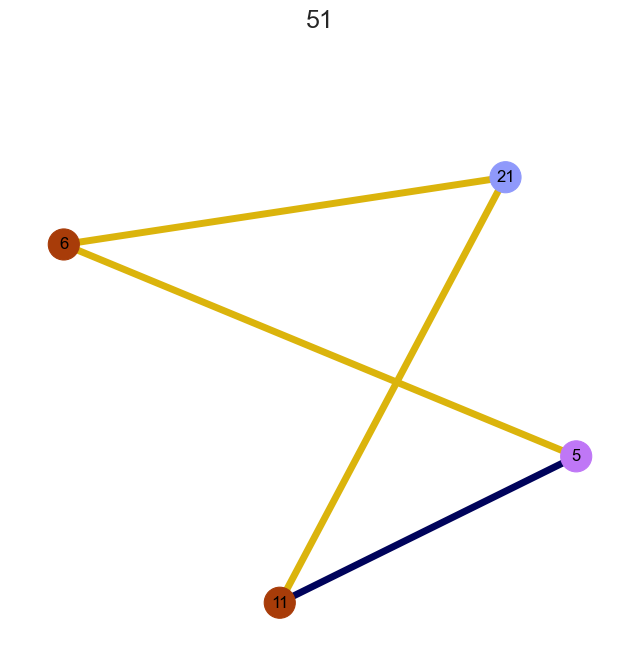

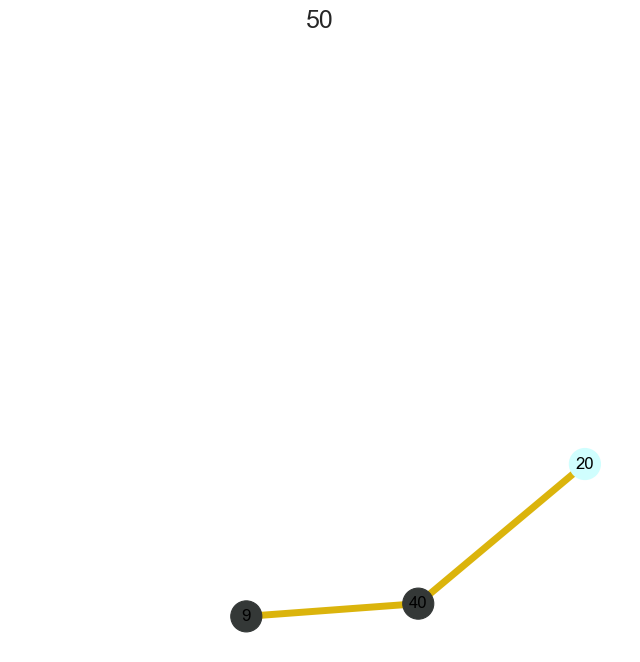

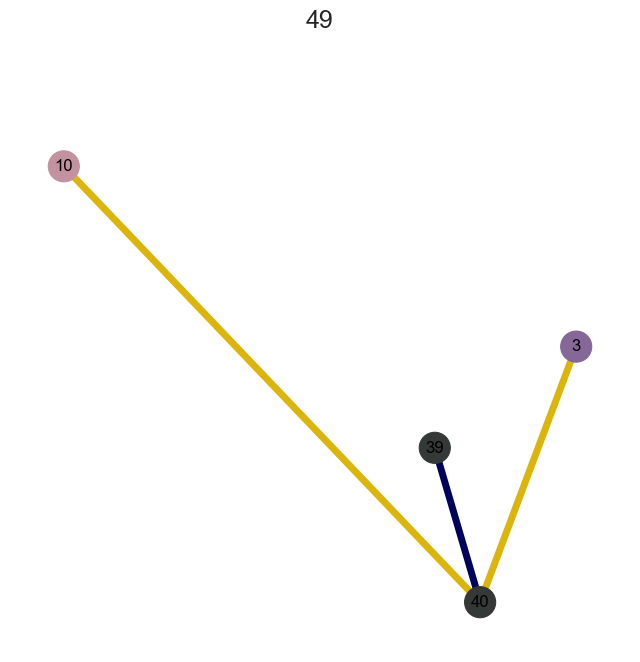

...

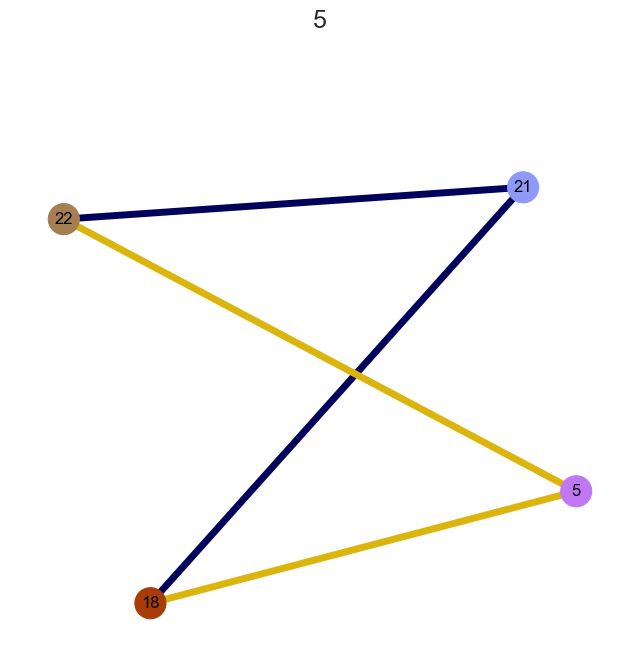

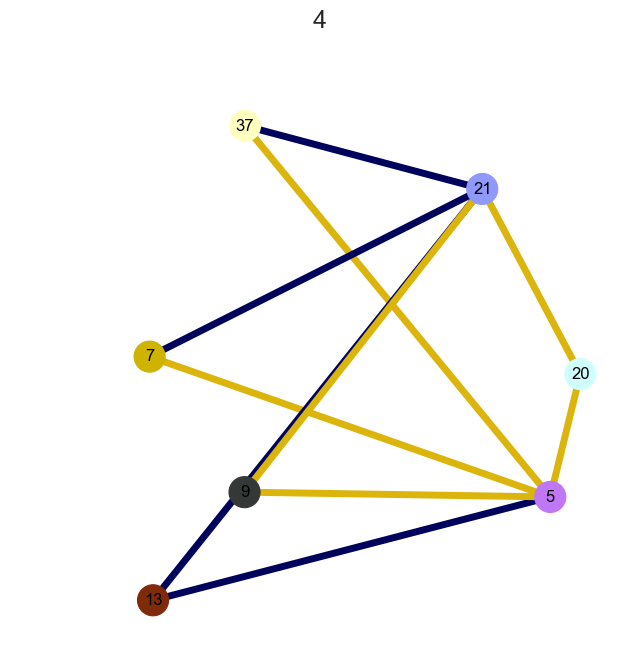

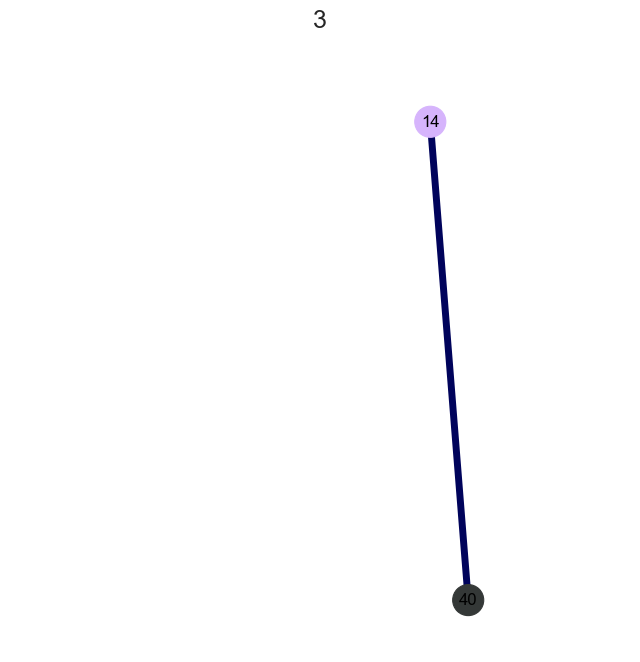

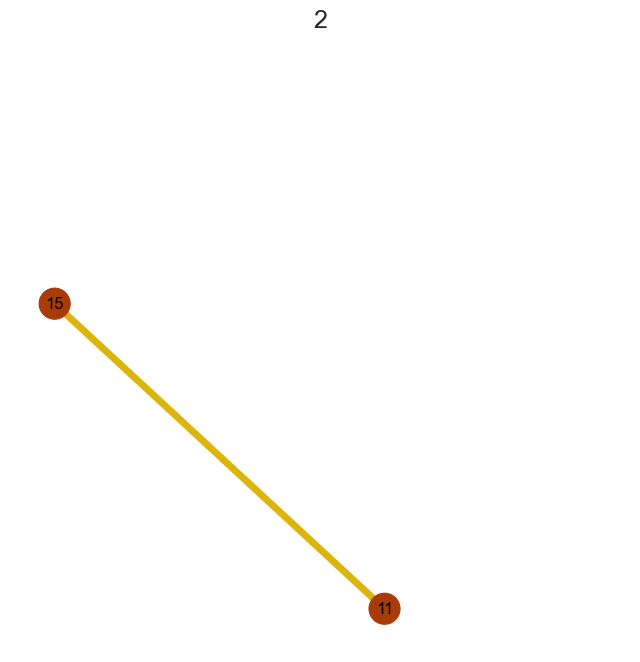

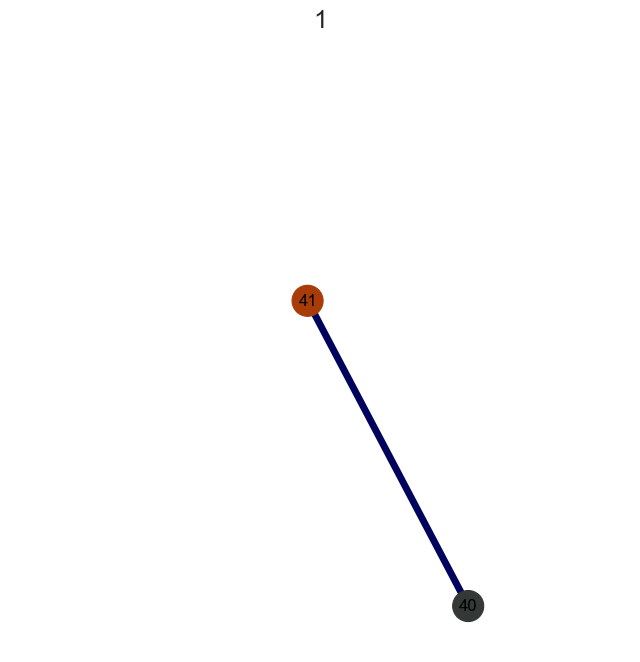

In [72]:
#Plot each link community individually
for i in list(range(53,0,-1)):
    link_comm_net_plotter(bin_num=None,comm_num=i,sig_link_comms=True,correlation=True)
    #plt.savefig(f'../figs/corr_net_matrix/link_com_{i}.png',dpi=300,bbox_inches='tight')

/var/folders/71/xm3vqjnn3xv2vtqkfhmrtzyh0000gp/T/ipykernel_66556/3013258986.py:110: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig,ax=plt.subplots(figsize=(8,8))


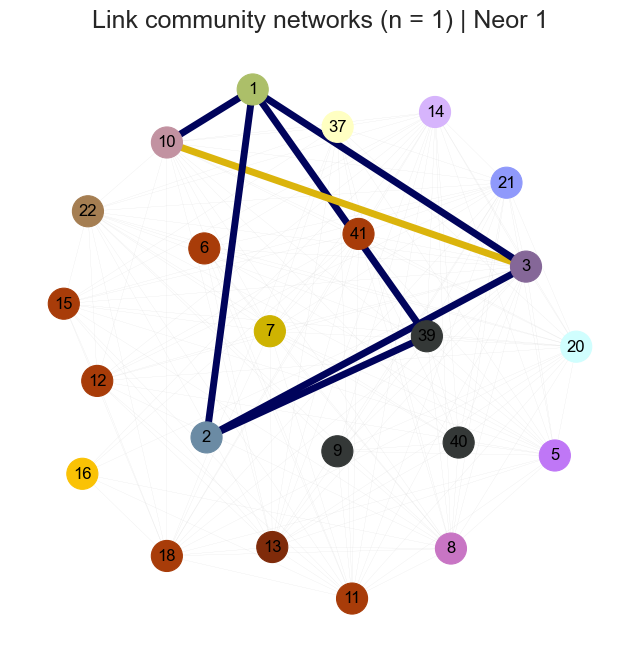

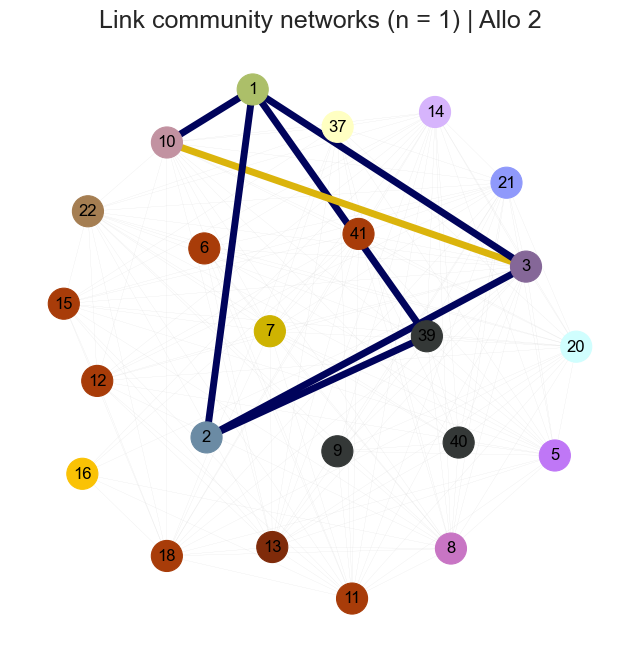

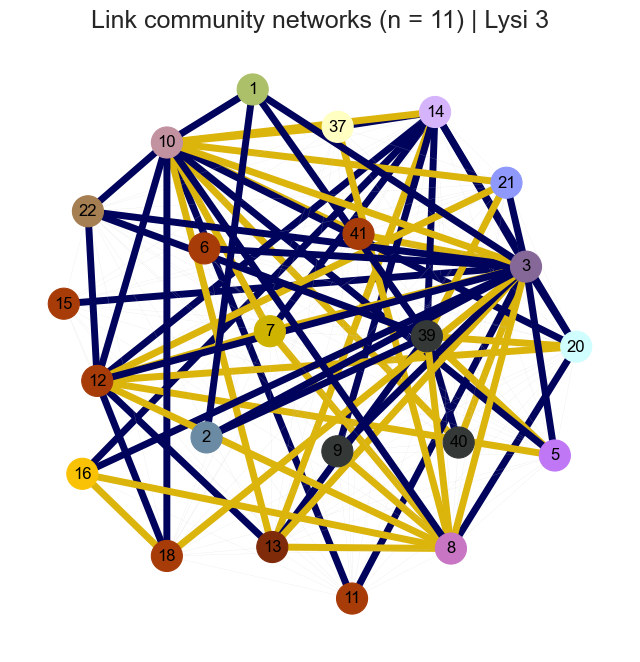

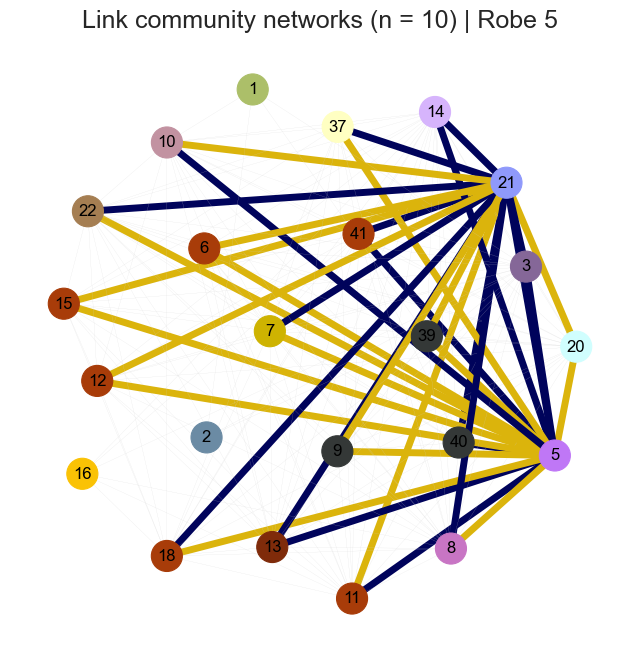

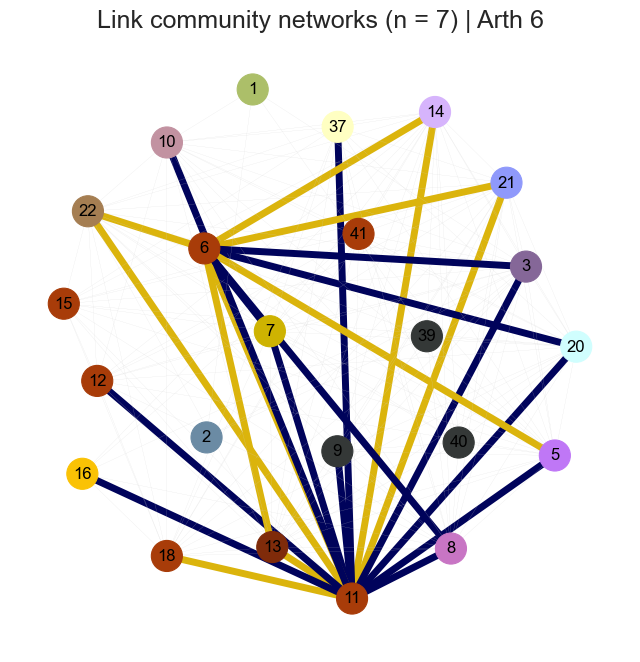

...

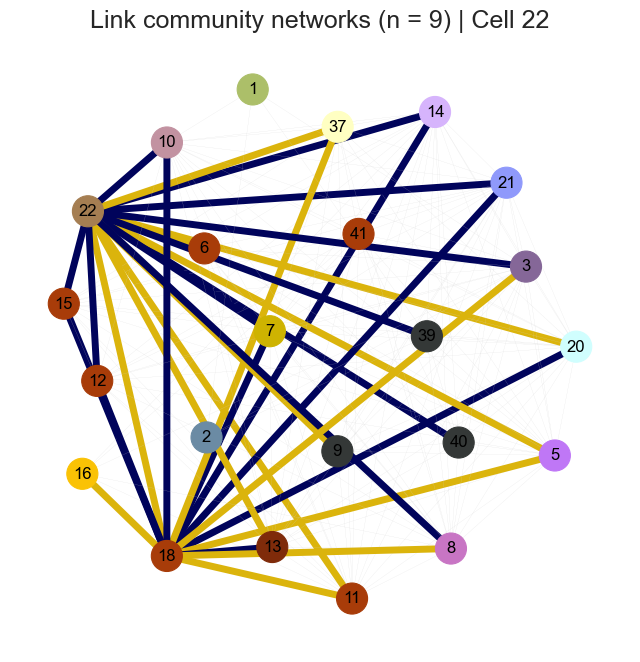

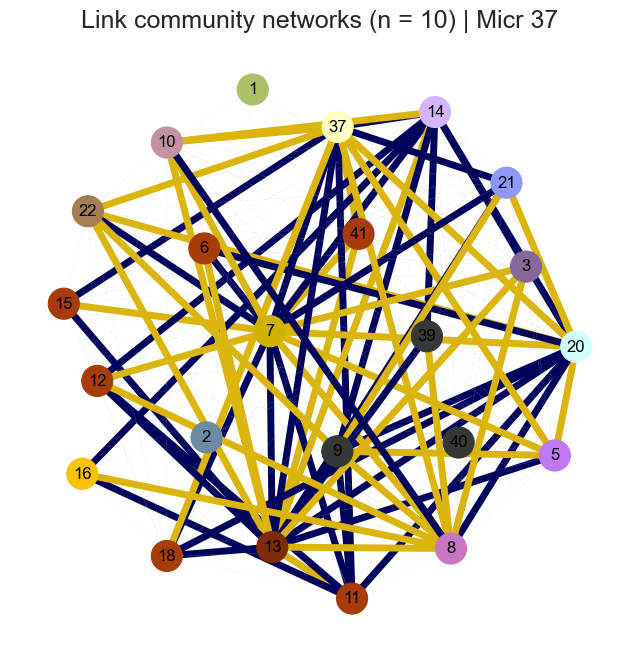

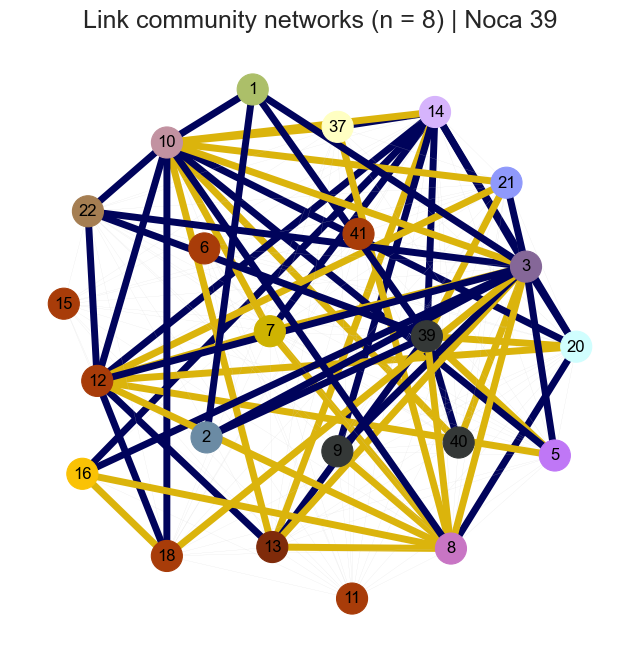

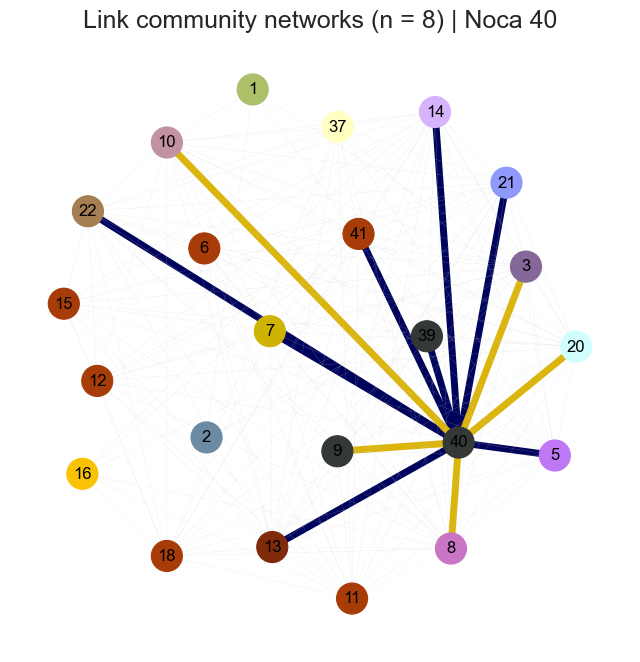

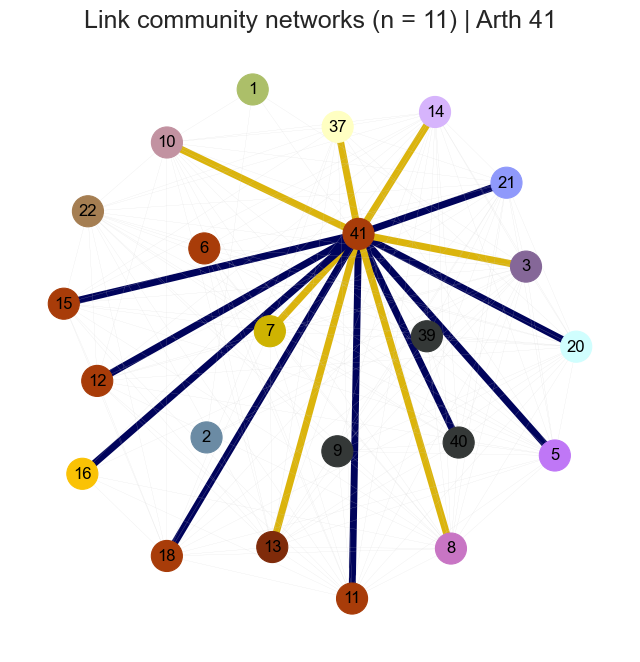

In [73]:
#Plot all of the link comms that each bin belongs too
for b in better_bin_list:
    link_comm_net_plotter(bin_num=b,comm_num=None,sig_link_comms=True,correlation=True)